# Overview {#sec-pca}




In [1]:
#| code-fold: true
#| code-summary: Code to prepare the environment

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba
import plotly.graph_objects as go

curfolder = os.getcwd()

# This is where our features live
features = os.path.join(curfolder, 'Datasets')
df = pd.read_csv(os.path.join(features, 'sapiens_features_noconcept_noLP.csv'))

df.head()

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__magnitude__flexion_speed_mean,fine__variability__flexion_speed_std,fine__smoothness__flexion_intermittency,fine__coordination__finger_independence,fine__variability__flexion_entropy,fileID,group,groupID,concept,pcnID
0,0.571581,0.557563,1.622492,0.660918,4,0.851064,1.339041,3.123783,3.113301,7.652372,...,0.409589,0.052382,26.111546,0.398712,2.782619,GP01_ANSTECKEN,GP01,Gesture,ANSTECKEN,GP01
1,0.065771,0.066443,0.102775,0.096030,10,2.127660,0.060660,0.321925,0.378740,0.571819,...,0.083279,0.008405,25.725000,0.317245,2.535043,GP01_ARBEITEN,GP01,Gesture,ARBEITEN,GP01
2,0.086983,0.098598,0.127089,0.143328,11,2.323944,0.070746,0.414123,0.532899,0.842822,...,0.116758,0.023732,25.799489,0.204966,2.255708,GP01_ARGUMENTIEREN,GP01,Gesture,ARGUMENTIEREN,GP01
3,1.095770,0.716163,2.004221,1.085136,5,1.056338,1.468796,4.542070,3.996176,7.684888,...,1.804326,0.255707,26.600159,0.145006,3.059892,GP01_BODEN,GP01,Gesture,BODEN,GP01
4,0.988528,0.865725,1.775825,1.086038,8,1.702128,1.395373,5.206694,4.021350,8.770024,...,1.213926,0.619982,26.730224,0.209743,2.876980,GP01_BRIEF,GP01,Gesture,BRIEF,GP01


In [2]:
# Show me proportion of missing values for each column
missing_values = df.isnull().mean() * 100
missing_values = missing_values[missing_values > 0]
print("Proportion of missing values in each column:")
missing_values

Proportion of missing values in each column:


gross__variability__arm_speed_peak_std       0.4
gross__rhythm__arm_speed_mod_depth           0.4
gross__rhythm__band1_band_power_totalarm     0.2
gross__rhythm__band1_centroid_totalarm       0.2
gross__rhythm__band1_peak_freq_totalarm     19.1
gross__rhythm__band1_entropy_totalarm        0.7
gross__rhythm__band3_peak_freq_totalarm     70.5
dtype: float64

In [3]:
# drop gross__rhythm__band1_peak_freq_totalarm, and gross__rhythm__band3_peak_freq_totalarm
df = df.drop(columns=['gross__rhythm__band1_peak_freq_totalarm', 'gross__rhythm__band3_peak_freq_totalarm'])

In [4]:
# how many rows if the df have any missing value
rows_with_missing_values = df[df.isnull().any(axis=1)]
print(f"Number of rows with missing values: {len(rows_with_missing_values)}")

# frop rows with missing values
df = df.dropna()
print(f"Number of rows after dropping missing values: {len(df)}")

Number of rows with missing values: 11
Number of rows after dropping missing values: 989


In [5]:
# how many rows in total?
total_rows = len(df)
print(f"Total number of rows: {total_rows}")

Total number of rows: 989


In [6]:
# how many columns is there
total_columns = len(df.columns)
print(f"Total number of columns: {total_columns}")

Total number of columns: 52


In [ ]:
sampled_df = df.copy()

# how many unique groupID are there?
unique_groupIDs = sampled_df['groupID'].nunique()
print(f"Number of unique groupIDs: {unique_groupIDs}")

# get rid of LP group
sampled_df = sampled_df[sampled_df['groupID'] != 'LP']

# show them
print("Unique groupIDs:")
print(sampled_df['groupID'].unique())

Number of unique groupIDs: 4
Unique groupIDs:
['Gesture' 'Sign' 'Learner_1' 'Learner_2']


In [8]:
sampled_df.head(50)

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__magnitude__flexion_speed_mean,fine__variability__flexion_speed_std,fine__smoothness__flexion_intermittency,fine__coordination__finger_independence,fine__variability__flexion_entropy,fileID,group,groupID,concept,pcnID
0,0.571581,0.557563,1.622492,0.660918,4,0.851064,1.339041,3.123783,3.113301,7.652372,...,0.409589,0.052382,26.111546,0.398712,2.782619,GP01_ANSTECKEN,GP01,Gesture,ANSTECKEN,GP01
1,0.065771,0.066443,0.102775,0.096030,10,2.127660,0.060660,0.321925,0.378740,0.571819,...,0.083279,0.008405,25.725000,0.317245,2.535043,GP01_ARBEITEN,GP01,Gesture,ARBEITEN,GP01
2,0.086983,0.098598,0.127089,0.143328,11,2.323944,0.070746,0.414123,0.532899,0.842822,...,0.116758,0.023732,25.799489,0.204966,2.255708,GP01_ARGUMENTIEREN,GP01,Gesture,ARGUMENTIEREN,GP01
3,1.095770,0.716163,2.004221,1.085136,5,1.056338,1.468796,4.542070,3.996176,7.684888,...,1.804326,0.255707,26.600159,0.145006,3.059892,GP01_BODEN,GP01,Gesture,BODEN,GP01
4,0.988528,0.865725,1.775825,1.086038,8,1.702128,1.395373,5.206694,4.021350,8.770024,...,1.213926,0.619982,26.730224,0.209743,2.876980,GP01_BRIEF,GP01,Gesture,BRIEF,GP01
5,0.446677,0.516632,1.460609,0.723353,3,0.638298,1.198587,2.181750,2.645087,6.859728,...,1.431235,0.351053,25.868901,0.148617,2.395799,GP01_BUERO,GP01,Gesture,BUERO,GP01
6,0.049132,0.043666,0.065808,0.064144,8,1.702128,0.040018,0.225281,0.251191,0.321962,...,0.072847,0.007774,25.399774,0.398092,2.692648,GP01_DRECK,GP01,Gesture,DRECK,GP01
7,0.533584,0.750673,1.040569,0.856015,5,1.063830,0.606795,2.501264,3.501456,7.839884,...,0.783768,0.073565,25.896497,0.095695,2.536669,GP01_ENTSCHULDIGEN,GP01,Gesture,ENTSCHULDIGEN,GP01
8,1.230459,1.040059,2.911234,1.059818,4,0.851064,2.660828,6.044999,5.642434,13.152024,...,0.564986,0.070721,25.979918,0.176155,2.858055,GP01_GIRAFFE,GP01,Gesture,GIRAFFE,GP01
9,0.962667,1.320535,3.045905,2.321305,3,0.638298,2.888354,4.996185,6.638067,13.577851,...,0.711325,0.098395,25.994630,0.033304,2.388043,GP01_GOTT,GP01,Gesture,GOTT,GP01


In [9]:
#| code-fold: true
#| code-summary: Custom functions

# Function to clean the data
def clean_df(df):

    # Fill NaNs with 0
    df = df.fillna(0)   # FLAGGED: this we might change, maybe not the best method (alternative: MICE)

    # Save values from groupID
    groupID = df['groupID']
    concepts = df['concept']

    # Leave only numerical cols, except groupID
    df = df.select_dtypes(include=['float64','int64'])

    # Add back correction_info
    df['groupID'] = groupID
    df['concept'] = concepts
    
    return df

In [10]:
# Clean the df
df_clean = clean_df(sampled_df)

df_clean.head(15)

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__handshape__handshape_size_mean,fine__variability__handshape_size_std,fine__variability__handshape_variability,fine__magnitude__flexion_speed_mean,fine__variability__flexion_speed_std,fine__smoothness__flexion_intermittency,fine__coordination__finger_independence,fine__variability__flexion_entropy,groupID,concept
0,0.571581,0.557563,1.622492,0.660918,4,0.851064,1.339041,3.123783,3.113301,7.652372,...,1.282660,0.597304,0.309220,0.409589,0.052382,26.111546,0.398712,2.782619,Gesture,ANSTECKEN
1,0.065771,0.066443,0.102775,0.096030,10,2.127660,0.060660,0.321925,0.378740,0.571819,...,1.436771,0.661582,0.199937,0.083279,0.008405,25.725000,0.317245,2.535043,Gesture,ARBEITEN
2,0.086983,0.098598,0.127089,0.143328,11,2.323944,0.070746,0.414123,0.532899,0.842822,...,1.467670,0.701509,0.201170,0.116758,0.023732,25.799489,0.204966,2.255708,Gesture,ARGUMENTIEREN
3,1.095770,0.716163,2.004221,1.085136,5,1.056338,1.468796,4.542070,3.996176,7.684888,...,1.203966,0.617083,0.953304,1.804326,0.255707,26.600159,0.145006,3.059892,Gesture,BODEN
4,0.988528,0.865725,1.775825,1.086038,8,1.702128,1.395373,5.206694,4.021350,8.770024,...,1.155115,0.595067,1.505369,1.213926,0.619982,26.730224,0.209743,2.876980,Gesture,BRIEF
5,0.446677,0.516632,1.460609,0.723353,3,0.638298,1.198587,2.181750,2.645087,6.859728,...,1.211366,0.573463,0.665747,1.431235,0.351053,25.868901,0.148617,2.395799,Gesture,BUERO
6,0.049132,0.043666,0.065808,0.064144,8,1.702128,0.040018,0.225281,0.251191,0.321962,...,1.409923,0.635559,0.160547,0.072847,0.007774,25.399774,0.398092,2.692648,Gesture,DRECK
7,0.533584,0.750673,1.040569,0.856015,5,1.063830,0.606795,2.501264,3.501456,7.839884,...,1.350118,0.635166,0.417164,0.783768,0.073565,25.896497,0.095695,2.536669,Gesture,ENTSCHULDIGEN
8,1.230459,1.040059,2.911234,1.059818,4,0.851064,2.660828,6.044999,5.642434,13.152024,...,1.447490,0.706488,0.401188,0.564986,0.070721,25.979918,0.176155,2.858055,Gesture,GIRAFFE
9,0.962667,1.320535,3.045905,2.321305,3,0.638298,2.888354,4.996185,6.638067,13.577851,...,1.367287,0.660070,0.634057,0.711325,0.098395,25.994630,0.033304,2.388043,Gesture,GOTT


In [11]:
# save it 

df_clean.to_csv(os.path.join(features, 'sampled_merged_sapiens.csv'), index=False)

In [12]:
df_clean = pd.read_csv(os.path.join(features, 'sampled_merged_sapiens.csv'))

# check whether there is a concept that occurs for all groupIDs
concept_group_counts = df_clean.groupby('concept')['groupID'].nunique()

# show the concepts that occur for all groupIDs
concepts_all_groupIDs = concept_group_counts[concept_group_counts == unique_groupIDs].index
print("Concepts that occur for all groupIDs:")
print(concepts_all_groupIDs)


Concepts that occur for all groupIDs:
Index([], dtype='object', name='concept')


# Testing approprietness of PCA

In [13]:
from scipy.stats import pearsonr

# keep only numerical columns for correlation analysis
numerical_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
df_numerical = df_clean[numerical_cols]

# Compute raw correlations
X_raw = df_numerical #.iloc[:, :-1].values  # unscaled features

obs_rs = []
obs_pvals = []

for i in range(X_raw.shape[1]):
    for j in range(i+1, X_raw.shape[1]):
        r, p = pearsonr(X_raw.iloc[:, i], X_raw.iloc[:, j])
        obs_rs.append(r)
        obs_pvals.append(p)

obs_rs = np.array(obs_rs)
obs_pvals = np.array(obs_pvals)

# Compute permutation
null_sig_counts = []
null_rs_all = []

for _ in range(1000):
    X_perm = np.apply_along_axis(np.random.permutation, 0, X_raw)

    perm_rs = []
    perm_pvals = []

    for i in range(X_raw.shape[1]):
        for j in range(i+1, X_raw.shape[1]):
            r, p = pearsonr(X_perm[:, i], X_perm[:, j])
            perm_rs.append(r)
            perm_pvals.append(p)

    perm_rs = np.array(perm_rs)
    perm_pvals = np.array(perm_pvals)

    null_sig_counts.append(np.sum(perm_pvals < 0.05))
    null_rs_all.append(np.abs(perm_rs))

null_sig_counts = np.array(null_sig_counts)
null_rs_all = np.array(null_rs_all).ravel()


Plot permuted vs raw data

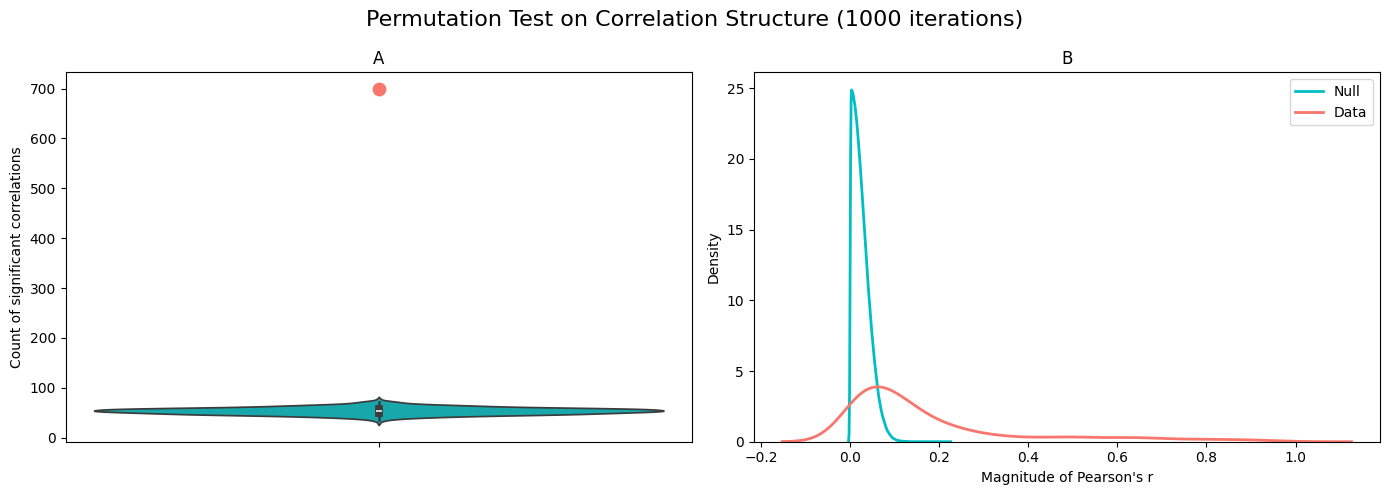

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

alpha = 0.05
obs_sig_count = np.sum(obs_pvals < alpha)
obs_abs_rs = np.abs(obs_rs)


plt.figure(figsize=(14, 5))

# Panel A: Count of significant correlations
plt.subplot(1, 2, 1)
sns.violinplot(y=null_sig_counts, color="#00BFC4")
plt.scatter([0], [obs_sig_count], color="#F8766D", s=80, zorder=5)
plt.ylabel("Count of significant correlations")
plt.title("A")

# Panel B: Magnitude of correlations
plt.subplot(1, 2, 2)
sns.kdeplot(null_rs_all, color="#00BFC4", linewidth=2, label="Null")
sns.kdeplot(obs_abs_rs, color="#F8766D", linewidth=2, label="Data")
plt.xlabel("Magnitude of Pearson's r")
plt.ylabel("Density")
plt.legend()
plt.title("B")

plt.suptitle("Permutation Test on Correlation Structure (1000 iterations)", fontsize=16)
plt.tight_layout()

# save the plot
plt.savefig(os.path.join(curfolder, "plots", "permutation_test_correlations.png"), dpi=300, bbox_inches='tight')
plt.show()


In [15]:
X_raw = df_numerical
feature_names = df_numerical.columns.to_list()

obs_corrs = []

for i in range(X_raw.shape[1]):
    for j in range(i+1, X_raw.shape[1]):
        r, p = pearsonr(X_raw.iloc[:, i], X_raw.iloc[:, j])
        obs_corrs.append({
            "feat1": feature_names[i],
            "feat2": feature_names[j],
            "r": r,
            "abs_r": abs(r),
            "p": p
        })

obs_corrs_df = pd.DataFrame(obs_corrs)

alpha = 0.05

obs_sig_count = np.sum(obs_corrs_df["p"] < alpha)

print("Correlation test results.")
print(f"Count of significant pairwise correlations in original data at alpha = {alpha}: {obs_sig_count}")
print(f"Mean significant pairwise correlations in permuted data (n = 1000) at alpha = {alpha}: {null_sig_counts.mean():.3f}")
print(f"Min = {null_sig_counts.min()}, Max = {null_sig_counts.max()}.")

top_n = 5

top_corrs = obs_corrs_df.sort_values("abs_r", ascending=False).head(top_n)

print("\nTop 5 pairwise correlations in original data:")
for _, row in top_corrs.iterrows():
    print(f"{row['feat1']}, {row['feat2']}: {row['r']:.2f}")



Correlation test results.
Count of significant pairwise correlations in original data at alpha = 0.05: 699
Mean significant pairwise correlations in permuted data (n = 1000) at alpha = 0.05: 53.730
Min = 29, Max = 78.

Top 5 pairwise correlations in original data:
fine__variability__fingertip_spread_std, fine__handshape__thumb_index_mean: 0.97
gross__magnitude__arm_acc_peak_mean, gross__rhythm__arm_acc_mod_depth: 0.96
gross__variability__arm_speed_Gstd, gross__variability__arm_acc_Gstd: 0.94
gross__rhythm__band3_centroid_totalarm, gross__rhythm__band3_entropy_totalarm: 0.93
gross__magnitude__arm_speed_Gmean, gross__magnitude__arm_acc_Gmean: 0.93


# PCA all froups (fine + gross)

<br>
Now, we first standardize the data and apply PCA to extract principal components. We use custom function  (adapted from [here](https://stackoverflow.com/questions/50796024/feature-variable-importance-after-a-pca-analysis)) to visualize the first two principal components. Data points are color-coded on the target variable (groupID) and red arrows represent the contributions of selected variables to the PC.

## Interactive Biplot

In [16]:
def interactive_PCA_biplot(score, coeff, labels=None, y=None, selected_vars=None, 
                            arrow_strength=None, pc_x=1, pc_y=2, show_labels=True,
                            concepts=None, highlight_concepts=None, le=None):
    ix, iy = pc_x - 1, pc_y - 1
    xs = score[:, ix]
    ys = score[:, iy]
    concepts = np.array(concepts) if concepts is not None else None

    if concepts is not None and len(concepts) != len(xs):
        print(f"Warning: concepts length ({len(concepts)}) doesn't match score rows ({len(xs)}). Ignoring concepts.")
        concepts = None

    def group_name(g):
        return le.inverse_transform([g])[0] if le is not None else f"Group {g}"

    # --- Discrete color mapping per group ---
    groups = np.unique(y)
    palette = [
        '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
        '#9467bd', '#8c564b', '#e377c2', '#7f7f7f'
    ]
    color_map = {g: palette[i % len(palette)] for i, g in enumerate(groups)}

    traces = []

    # --- One scatter trace per group ---
    for g in groups:
        mask = y == g
        traces.append(go.Scatter(
            x=xs[mask], y=ys[mask],
            mode='markers',
            marker=dict(size=8, color=color_map[g], opacity=0.6),
            name=group_name(g),
            text=[group_name(g) + (f"<br>{concepts[i]}" if concepts is not None else "")
                  for i in np.where(mask)[0]],
            hoverinfo='text',
            showlegend=True
        ))

    # --- Highlighted concept overlays ---
    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            mask = np.where(concepts == concept)[0]

            seen_groups = {}
            for idx in mask:
                group = y[idx]
                if group not in seen_groups:
                    seen_groups[group] = idx

            representative_indices = list(seen_groups.values())

            traces.append(go.Scatter(
                x=xs[representative_indices],
                y=ys[representative_indices],
                mode='markers',
                marker=dict(size=12, color='red', symbol='star',
                            line=dict(color='black', width=1)),
                name=concept,
                text=[f"{concept} — {group_name(y[i])}" for i in representative_indices],
                hoverinfo='text',
                showlegend=True
            ))

    # --- Arrows ---
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    base_scale = 10

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        scale = base_scale * (arrow_strength.get(var_name, 1.0) if arrow_strength else 1.0)

        traces.append(go.Scatter(
            x=[0, coeff[i, ix] * scale],
            y=[0, coeff[i, iy] * scale],
            mode='lines+markers+text' if show_labels else 'lines+markers',
            line=dict(color='black'),
            marker=dict(size=4),
            text=[None, var_name] if show_labels else None,
            textposition='top center',
            hovertext=var_name,
            hoverinfo='text',
            showlegend=False
        ))

    layout = go.Layout(
        title=f"Interactive PCA Biplot — PC{pc_x} vs PC{pc_y}",
        xaxis=dict(title=f'PC{pc_x}'),
        yaxis=dict(title=f'PC{pc_y}'),
        width=900, height=700,
        hovermode='closest',
    )

    go.Figure(data=traces, layout=layout).show()

In [17]:
# make concepts as list
concepts = df_clean['concept'].tolist()
# now get rid of concept col
df_clean = df_clean.drop(columns=['concept'])

print(f"concepts: {len(concepts)}, df_clean rows: {len(df_clean)}")  # sanity check

concepts: 989, df_clean rows: 989


In [18]:
# save it 

df_clean.to_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'), index=False)

In [19]:
# read it
df_clean = pd.read_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'))

In [78]:
def static_PCA_biplot(score, coeff, labels=None, y=None, selected_vars=None,
                      arrow_strength=None, pc_x=1, pc_y=2, show_labels=True,
                      concepts=None, highlight_concepts=None, le=None,
                      figsize=(12, 9), save_path=None, dpi=300):
    """
    Presentation-quality static PCA biplot with centroids.

    Parameters
    ----------
    score           : np.ndarray, shape (n_samples, n_components)
    coeff           : np.ndarray, shape (n_vars, n_components)
    labels          : list of str, variable names for arrows
    y               : np.ndarray, group labels (int or str)
    selected_vars   : list of int, indices of variables to draw arrows for
    arrow_strength  : dict {var_name: scale_factor}
    pc_x, pc_y      : int, which PCs to plot (1-indexed)
    show_labels     : bool, annotate arrow tips with variable names
    concepts        : np.ndarray, concept label per sample
    highlight_concepts : list of str, concepts to highlight with star markers
    le              : sklearn LabelEncoder for decoding group labels
    figsize         : tuple
    save_path       : str or None — if given, saves figure to this path
    dpi             : int, resolution for saved figure
    """

    ix, iy = pc_x - 1, pc_y - 1
    xs = score[:, ix]
    ys = score[:, iy]
    concepts = np.array(concepts) if concepts is not None else None

    if concepts is not None and len(concepts) != len(xs):
        print(f"Warning: concepts length ({len(concepts)}) doesn't match score rows ({len(xs)}). Ignoring.")
        concepts = None

    def group_name(g):
        return le.inverse_transform([g])[0] if le is not None else f"Group {g}"

    # ── Palette ───────────────────────────────────────────────────────────────
    PALETTE = [
        "#878787", "#77AB00", "#00BCC2", "#8B3FAB",
        "#8172B3", "#937860", "#DA8BC3", "#8C8C8C",
    ]
    groups = np.unique(y)
    color_map = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(groups)}

    # ── Figure setup ──────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize, facecolor="#FAFAFA")
    ax.set_facecolor("#FAFAFA")

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
        spine.set_color("#CCCCCC")

    ax.axhline(0, color="#CCCCCC", linewidth=0.8, zorder=0)
    ax.axvline(0, color="#CCCCCC", linewidth=0.8, zorder=0)
    ax.grid(True, linestyle="--", linewidth=0.5, color="#E0E0E0", zorder=0)

    # ── Scatter per group ─────────────────────────────────────────────────────
    for g in groups:
        mask = y == g
        c = color_map[g]
        ax.scatter(
            xs[mask], ys[mask],
            color=to_rgba(c, 0.55),
            edgecolors=to_rgba(c, 0.85),
            linewidths=0.5,
            s=85,
            zorder=2,
            label=group_name(g),
        )

    # ── Centroids ─────────────────────────────────────────────────────────────
    for g in groups:
        mask = y == g
        cx, cy = xs[mask].mean(), ys[mask].mean()
        c = color_map[g]
        ax.scatter(
            cx, cy,
            color=c,
            edgecolors="white",
            linewidths=1.8,
            s=200,
            marker="X",
            zorder=5,
        )
        ax.annotate(
            group_name(g),
            xy=(cx, cy),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color=c,
            zorder=6,
        )

    # ── Highlighted concepts ──────────────────────────────────────────────────
    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            idx_all = np.where(concepts == concept)[0]
            seen_groups = {}
            for idx in idx_all:
                g = y[idx]
                if g not in seen_groups:
                    seen_groups[g] = idx
            rep_indices = list(seen_groups.values())

            ax.scatter(
                xs[rep_indices], ys[rep_indices],
                color="crimson",
                edgecolors="black",
                linewidths=0.8,
                s=180,
                marker="*",
                zorder=7,
                label=concept,
            )

    # ── Arrows ────────────────────────────────────────────────────────────────
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    base_scale = 10

    arrowprops = dict(
        arrowstyle="-|>",
        color="#2B2B2B",
        lw=1.5,
        mutation_scale=12,
    )

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        scale = base_scale * (arrow_strength.get(var_name, 1.0) if arrow_strength else 1.0)
        ex, ey = coeff[i, ix] * scale, coeff[i, iy] * scale

        ax.annotate(
            "",
            xy=(ex, ey),
            xytext=(0, 0),
            arrowprops=arrowprops,
            zorder=4,
        )

        if show_labels:
            # Nudge label slightly beyond arrow tip
            offset = 0.05 * np.array([ex, ey])
            ax.text(
                ex + offset[0], ey + offset[1],
                var_name,
                fontsize=8.5,
                ha="center",
                va="center",
                color="#2B2B2B",
                fontweight="semibold",
                bbox=dict(
                    boxstyle="round,pad=0.2",
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.75,
                ),
                zorder=5,
            )

    # ── Labels & title ────────────────────────────────────────────────────────
    ax.set_xlabel(f"PC{pc_x}", fontsize=13, labelpad=8, color="#333333")
    ax.set_ylabel(f"PC{pc_y}", fontsize=13, labelpad=8, color="#333333")
    ax.set_title(
        f"PCA Biplot — PC{pc_x} vs PC{pc_y}",
        fontsize=15,
        fontweight="bold",
        color="#1A1A1A",
        pad=14,
    )
    ax.tick_params(colors="#555555", labelsize=9)

    # ── Legend (groups only, centroids explained in title note) ───────────────
    group_handles = [
        mpatches.Patch(color=color_map[g], label=group_name(g), alpha=0.8)
        for g in groups
    ]
    centroid_handle = plt.Line2D(
        [0], [0],
        marker="X",
        color="w",
        markerfacecolor="#555555",
        markeredgecolor="white",
        markersize=9,
        label="Centroid",
    )
    handles = group_handles + [centroid_handle]

    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            handles.append(
                plt.Line2D(
                    [0], [0],
                    marker="*",
                    color="w",
                    markerfacecolor="crimson",
                    markeredgecolor="black",
                    markersize=11,
                    label=concept,
                )
            )

    ax.legend(
        handles=handles,
        loc="best",
        fontsize=9,
        framealpha=0.9,
        edgecolor="#CCCCCC",
        fancybox=False,
    )

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Figure saved to: {save_path}")

    plt.show()
    return fig, ax

## PC1-PC2

In [21]:
feature_names = df_clean.columns[:-1].to_list()

# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features

df_clean['groupID'] = df_clean['groupID'].astype('category')
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler_GS = StandardScaler()
Xz_GS = scaler_GS.fit_transform(X)    

# PCA transformation
pca_GS = PCA()
x_new_GS = pca_GS.fit_transform(Xz_GS)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings_GS = pca_GS.components_.T

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # PC1 and PC2 (the PCs you plot below)
    component = loadings_GS[:, i]      # column i = all variables' loadings ON PC i
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                       concepts=concepts,
                       le=le,
                       highlight_concepts=None  # or None for no highlighting
                    
                    )

## PC2-PC3

In [22]:
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=2, 
                       pc_y=3,
                       concepts = concepts,
                       le=le,
                       show_labels=False)

## PC3-PC4

In [23]:
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=3, 
                       pc_y=4,
                       le=le,
                       show_labels=False)

## P4-P5

In [24]:
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=4, 
                       pc_y=5,
                       le=le,
                       show_labels=False)

In [25]:
print("Unique levels in target column:", np.unique(df_clean.iloc[:, -1]))

Unique levels in target column: ['Gesture' 'Learner_1' 'Learner_2' 'Sign']


## Bootstrap PCA

In [26]:
def bootstrap_pca(Xz, n_boot=1000):

    rng = np.random.default_rng(42)

    boot_loadings = []
    boot_eigs = []

    n = Xz.shape[0]

    for _ in range(n_boot):
        idx = rng.choice(n, n, replace=True)
        Xb = Xz[idx]
        pca_b = PCA().fit(Xb)
        boot_loadings.append(pca_b.components_.T)
        boot_eigs.append(pca_b.explained_variance_)

    boot_loadings = np.array(boot_loadings)
    boot_eigs = np.array(boot_eigs)

    # total variance per bootstrap PCA (needed to convert eigvals -> variance explained)
    boot_total_var = np.sum(boot_eigs, axis=1, keepdims=True)

    # bootstrap variance explained per PC
    boot_var_explained = boot_eigs / boot_total_var

    # mean and SD of bootstrap variance explained
    boot_var_mean = boot_var_explained.mean(axis=0)
    boot_var_sd = boot_var_explained.std(axis=0)

    # # sanity check shapes
    # print(boot_var_mean.shape, boot_var_sd.shape)

    loading_ci_low = np.percentile(boot_loadings, 5, axis=0)
    loading_ci_high = np.percentile(boot_loadings, 95, axis=0)

    eig_ci_low = np.percentile(boot_eigs, 2.5, axis=0)
    eig_ci_high = np.percentile(boot_eigs, 97.5, axis=0)

    # bind all results into a dictionary for easy access
    results = {
        "boot_loadings": boot_loadings,
        "boot_eigs": boot_eigs,
        "boot_var_mean": boot_var_mean,
        "boot_var_sd": boot_var_sd,
        "loading_ci_low": loading_ci_low,
        "loading_ci_high": loading_ci_high,
        "eig_ci_low": eig_ci_low,
        "eig_ci_high": eig_ci_high
    }

    return results

bootstrap_results_GS = bootstrap_pca(Xz_GS)

## Null PCA (permutation test)

In [27]:
def permutation_pca(Xz, n_boot=1000):

    rng = np.random.default_rng(42)

    null_loadings = []
    null_eigs = []

    for _ in range(n_boot):
        #
        Xnull = np.apply_along_axis(rng.permutation, 0, Xz)
        pca_n = PCA().fit(Xnull)
        null_loadings.append(pca_n.components_.T)
        null_eigs.append(pca_n.explained_variance_)

    null_loadings = np.array(null_loadings)
    null_eigs = np.array(null_eigs)

    null_loading_thresh = np.percentile(np.abs(null_loadings), 95, axis=0)
    null_eig_thresh = np.percentile(null_eigs, 95, axis=0)

    results = {
        "null_loadings": null_loadings,
        "null_eigs": null_eigs,
        "null_loading_thresh": null_loading_thresh,
        "null_eig_thresh": null_eig_thresh
    }

    return results

permutation_results_GS = permutation_pca(Xz_GS)


## Significance mask

In [28]:
# determine significant PCs
var_explained_GS = pca_GS.explained_variance_ratio_
null_var_thresh_GS = permutation_results_GS["null_eig_thresh"] / np.sum(pca_GS.explained_variance_)  # convert eig to variance ratio
sig_pc_null_GS = var_explained_GS > null_var_thresh_GS

In [29]:
sig_pc_effect_GS = var_explained_GS > 0.05  # 5% cut-off
sig_pc_GS = sig_pc_null_GS & sig_pc_effect_GS

print("Significant PCs:")
for i, sig in enumerate(sig_pc_GS, start=1):
    print(f"PC{i}: significant = {sig}, var explained = {var_explained_GS[i-1]:.3f}")

Significant PCs:
PC1: significant = True, var explained = 0.187
PC2: significant = True, var explained = 0.152
PC3: significant = True, var explained = 0.125
PC4: significant = True, var explained = 0.084
PC5: significant = True, var explained = 0.059
PC6: significant = False, var explained = 0.043
PC7: significant = False, var explained = 0.036
PC8: significant = False, var explained = 0.033
PC9: significant = False, var explained = 0.029
PC10: significant = False, var explained = 0.025
PC11: significant = False, var explained = 0.022
PC12: significant = False, var explained = 0.021
PC13: significant = False, var explained = 0.019
PC14: significant = False, var explained = 0.018
PC15: significant = False, var explained = 0.017
PC16: significant = False, var explained = 0.015
PC17: significant = False, var explained = 0.014
PC18: significant = False, var explained = 0.012
PC19: significant = False, var explained = 0.012
PC20: significant = False, var explained = 0.010
PC21: significant

In [30]:
import os
sig_idx = np.where(sig_pc_GS)[0]                       # significant PCs (null AND >=5%)
pc_cols = [f"PC{i+1}" for i in sig_idx]
scores  = pd.DataFrame(x_new_GS[:, sig_idx], columns=pc_cols)

meta = (sampled_df[['group', 'groupID', 'concept']]
        .reset_index(drop=True)
        .rename(columns={'group': 'participant'}))
assert len(meta) == len(scores), "row mismatch — metadata not aligned with PCA scores!"

out = pd.concat([scores, meta], axis=1)
for row in out.itertuples():
    if row.participant.startswith('IP'):
        out.loc[row.Index, 'participant'] = row.participant.split('_')[0]

out.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_all.csv'), index=False)

In [31]:
def plot_pca_variance(var_explained,
                             boot_ci_low,
                             boot_ci_high,
                             null_thresh,
                             max_pcs=20):
    """
    var_explained: array of variance explained ratios (e.g. pca.explained_variance_ratio_)
    boot_ci_low: bootstrap CI lower bound (variance ratio)
    boot_ci_high: bootstrap CI upper bound (variance ratio)
    null_thresh: null 95% threshold (variance ratio)
    """

    pcs = np.arange(1, len(var_explained) + 1)

    # optionally truncate to first N PCs (keeps plot readable)
    pcs = pcs[:max_pcs]
    var_explained = var_explained[:max_pcs]
    boot_ci_low = boot_ci_low[:max_pcs]
    boot_ci_high = boot_ci_high[:max_pcs]

    plt.figure(figsize=(10, 6))

    # CI bars
    plt.vlines(
        pcs,
        boot_ci_low * 100,
        boot_ci_high * 100,
        colors='black',
        linewidth=1,
        alpha=0.7
    )

    # observed variance points
    plt.scatter(
        pcs,
        var_explained * 100,
        color='red',
        s=40,
        zorder=3,
        label="Sampling"
    )

    # null threshold line
    plt.plot(
    pcs,
    null_thresh[:len(pcs)] * 100,
    linestyle='--',
    color='teal',
    linewidth=2,
    label="Null"
)


    plt.xlabel("Principal Component")
    plt.ylabel("Variance Explained (%)")
    plt.title("Variance Explained by Principal Components")

    plt.xticks(pcs, [f"PC{i}" for i in pcs], rotation=90)
    plt.legend()
    plt.tight_layout()
    plt.show()


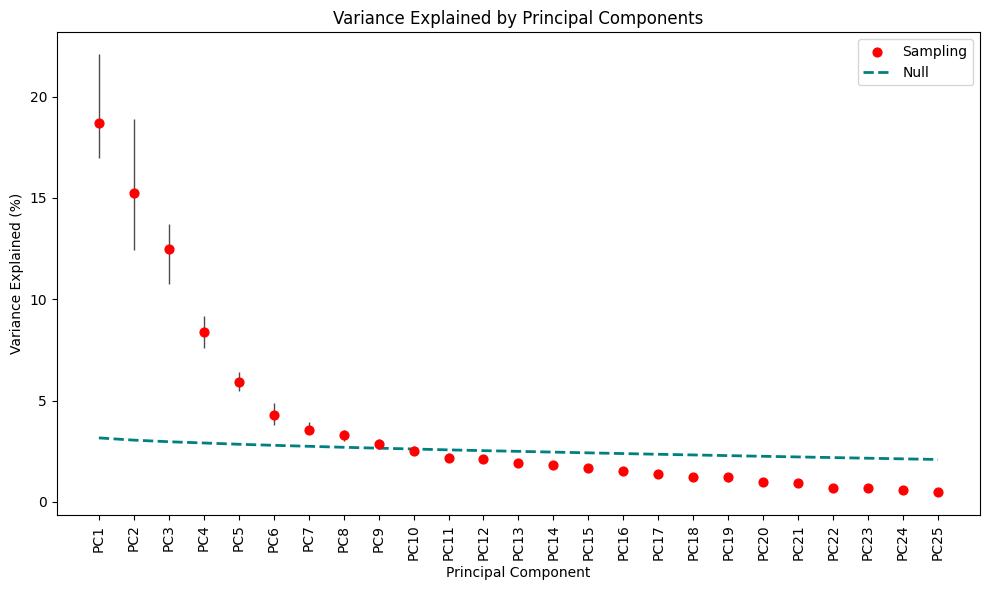

<Figure size 640x480 with 0 Axes>

In [32]:
boot_var_ci_low_GS = bootstrap_results_GS["eig_ci_low"] / np.sum(pca_GS.explained_variance_)
boot_var_ci_high_GS = bootstrap_results_GS["eig_ci_high"] / np.sum(pca_GS.explained_variance_)
null_var_thresh_GS = permutation_results_GS["null_eig_thresh"] / np.sum(pca_GS.explained_variance_)

plot_pca_variance(
    var_explained=pca_GS.explained_variance_ratio_,
    boot_ci_low=boot_var_ci_low_GS,
    boot_ci_high=boot_var_ci_high_GS,
    null_thresh=null_var_thresh_GS,
    max_pcs=25   # adjust for readability
)

# save this plot
plt.savefig(os.path.join(curfolder, "Plots", "GS_all_pca_variance_explained.png"), dpi=300, bbox_inches='tight')

In [33]:
n_pcs = len(pca_GS.explained_variance_ratio_)

pc_names = [f"PC{i+1}" for i in range(n_pcs)]

df_variance_GS = pd.DataFrame({
    "PC": pc_names,
    "variance_explained": pca_GS.explained_variance_ratio_,
    "low_confint_var": boot_var_ci_low_GS,
    "high_confint_var": boot_var_ci_high_GS,
    "mean_confint_var": bootstrap_results_GS["boot_var_mean"],
    "sd_confint_var": bootstrap_results_GS["boot_var_sd"],
    "null_thresh": null_var_thresh_GS
})

# significance: observed variance > null threshold
df_variance_GS["sig_PC"] = df_variance_GS["variance_explained"] > df_variance_GS["null_thresh"]

# filter significant PCs
df_sig_pcs_GS = df_variance_GS.loc[df_variance_GS["sig_PC"], [
    "PC",
    "variance_explained",
    "low_confint_var",
    "high_confint_var",
    "mean_confint_var",
    "sd_confint_var"
]]

# convert to %
df_sig_pcs_GS.loc[:, df_sig_pcs_GS.columns != "PC"] *= 100

df_sig_pcs_GS


,PC,variance_explained,low_confint_var,high_confint_var,mean_confint_var,sd_confint_var
0,PC1,18.691352,16.984968,22.087052,19.225686,1.024396
1,PC2,15.229874,12.420477,18.869538,15.224432,1.290442
2,PC3,12.454939,10.757408,13.688057,12.210640,0.638517
3,PC4,8.388774,7.616393,9.151797,8.407118,0.431967
4,PC5,5.916744,5.474645,6.433081,5.957134,0.284059
5,PC6,4.285026,3.800031,4.898560,4.350278,0.272781
6,PC7,3.570122,3.357272,3.918051,3.639829,0.179557
7,PC8,3.287447,3.004493,3.558220,3.294348,0.160568
8,PC9,2.857847,2.633118,3.097608,2.872819,0.130577


## Significant variables

Which variables are significant?

In [34]:
def identify_sigvar(pca, bootstrap_results, permutation_results, df_clean):

    # compute index loadings
    loadings = pca.components_.T
    eigs = pca.explained_variance_

    # index loadings for original PCA
    index_loadings = (loadings ** 2) * (eigs ** 2)

    # compute bootrap index loadings
    boot_index_loadings = (bootstrap_results["boot_loadings"] ** 2) * (bootstrap_results["boot_eigs"][:, None, :] ** 2)

    # 90% CI (matches loadings_confint = 0.9)
    low_q = 5
    high_q = 95

    boot_index_ci_low = np.percentile(boot_index_loadings, low_q, axis=0)
    boot_index_ci_high = np.percentile(boot_index_loadings, high_q, axis=0)

    # compute null index loadings
    null_index_loadings = (permutation_results["null_loadings"] ** 2) * (permutation_results["null_eigs"][:, None, :] ** 2)

    null_index_ci_low = np.percentile(null_index_loadings, low_q, axis=0)
    null_index_ci_high = np.percentile(null_index_loadings, high_q, axis=0)

    sig_vars = []

    for pc in range(loadings.shape[1]):
        for feat in range(loadings.shape[0]):
            sig_vars.append({
                "PC": pc + 1,
                "feature": df_clean.columns[feat],
                "loading": loadings[feat, pc],
                "index_loading": index_loadings[feat, pc],
                "low_confint": boot_index_ci_low[feat, pc],
                "high_confint": boot_index_ci_high[feat, pc],
                "low_null": null_index_ci_low[feat, pc],
                "high_null": null_index_ci_high[feat, pc],
                "sig_loading": index_loadings[feat, pc] > null_index_ci_high[feat, pc]
            })

    df_sig_vars = pd.DataFrame(sig_vars)

    return df_sig_vars

In [35]:
df_sig_vars_GS = identify_sigvar(pca_GS, bootstrap_results_GS, permutation_results_GS, df_clean)
df_sig_vars_GS[df_sig_vars_GS["sig_loading"]].sort_values(["PC", "index_loading"], ascending=[True, False])

,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
1,1,gross__variability__arm_speed_Gstd,0.311720,7.514247,0.279582,9.797834,0.000160,0.172881,True
2,1,gross__magnitude__arm_speed_peak_mean,0.297722,6.854520,0.271295,8.940949,0.000191,0.168061,True
8,1,gross__variability__arm_acc_Gstd,0.296355,6.791728,0.297578,9.460140,0.000149,0.152141,True
9,1,gross__magnitude__arm_acc_peak_mean,0.295038,6.731515,0.334646,9.242103,0.000146,0.141194,True
13,1,gross__rhythm__arm_acc_mod_depth,0.286389,6.342597,0.257979,8.521878,0.000163,0.162229,True
...,...,...,...,...,...,...,...,...,...
609,13,fine__coordination__finger_independence,-0.392426,0.124490,0.000946,0.195848,0.000168,0.114363,True
594,13,gross__proxdist__proximalization_index,-0.372853,0.112381,0.000809,0.237188,0.000188,0.104614,True
631,14,gross__rhythm__band1_entropy_totalarm,0.474310,0.165055,0.000927,0.242840,0.000071,0.105164,True
639,14,gross__coordination__arm_coupling,0.443693,0.144434,0.000827,0.205700,0.000140,0.109600,True


In [36]:
for pc in df_sig_pcs_GS["PC"]:
    pc_no = int(pc.replace("PC", ""))
    print(f"\nPC{pc_no} significant contributors:")
    display(
        df_sig_vars_GS[(df_sig_vars_GS["PC"] == pc_no) & (df_sig_vars_GS["sig_loading"])]
        .sort_values("index_loading", ascending=False)
        .head(10)
    )


PC1 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
1,1,gross__variability__arm_speed_Gstd,0.311720,7.514247,0.279582,9.797834,0.000160,0.172881,True
2,1,gross__magnitude__arm_speed_peak_mean,0.297722,6.854520,0.271295,8.940949,0.000191,0.168061,True
8,1,gross__variability__arm_acc_Gstd,0.296355,6.791728,0.297578,9.460140,0.000149,0.152141,True
9,1,gross__magnitude__arm_acc_peak_mean,0.295038,6.731515,0.334646,9.242103,0.000146,0.141194,True
13,1,gross__rhythm__arm_acc_mod_depth,0.286389,6.342597,0.257979,8.521878,0.000163,0.162229,True
6,1,gross__rhythm__arm_speed_mod_depth,0.285016,6.281943,0.239069,7.837777,0.000184,0.163568,True
7,1,gross__magnitude__arm_acc_Gmean,0.229826,4.084631,0.143641,6.871261,0.000202,0.153822,True
10,1,gross__variability__arm_acc_peak_std,0.207392,3.326128,0.194383,4.654743,0.000176,0.165522,True
27,1,gross__magnitude__bbmv_arms_total,0.195130,2.944445,0.104531,4.688431,0.000219,0.154935,True
14,1,gross__magnitude__arm_speed_integral,0.194306,2.919643,0.124058,5.157616,0.000217,0.162850,True



PC2 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
86,2,fine__handshape__handshape_size_mean,0.296090,4.501059,0.112132,5.798116,0.000394,0.148970,True
80,2,fine__handshape__thumb_index_mean,0.294179,4.443137,0.090945,6.140792,0.000191,0.159493,True
87,2,fine__variability__handshape_size_std,0.290582,4.335159,0.134018,5.798450,0.000336,0.142709,True
79,2,fine__variability__fingertip_spread_std,0.288531,4.274176,0.107014,6.154651,0.000151,0.146908,True
78,2,fine__handshape__fingertip_spread_mean,0.283675,4.131524,0.064341,5.379936,0.000259,0.138460,True
82,2,fine__handshape__mcp_tip_mean,0.282608,4.100486,0.099651,5.976552,0.000230,0.154182,True
83,2,fine__variability__mcp_tip_std,0.255771,3.358680,0.102523,5.372525,0.000206,0.143911,True
81,2,fine__variability__thumb_index_std,0.243249,3.037880,0.078386,4.215449,0.000171,0.146402,True
88,2,fine__variability__handshape_variability,0.235692,2.852047,0.068933,3.980110,0.000216,0.151962,True
84,2,fine__handshape__thumb_opposition_mean,0.186615,1.787971,0.018071,2.248665,0.000360,0.154167,True



PC3 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
106,3,gross__rhythm__arm_acc_peak_rate,0.307673,3.250393,0.514607,3.846114,0.000267,0.151196,True
118,3,gross__rhythm__band3_band_power_totalarm,0.303152,3.155573,0.465279,3.905870,0.000238,0.144642,True
112,3,gross__rhythm__band1_band_power_totalarm,-0.302398,3.139892,0.494845,3.777720,0.000204,0.137988,True
99,3,gross__rhythm__arm_speed_peak_rate,0.300173,3.093867,0.438422,3.724697,0.000225,0.149852,True
94,3,gross__magnitude__arm_speed_Gmean,0.257360,2.274266,0.232624,3.087104,0.000332,0.134256,True
98,3,gross__rhythm__arm_speed_peak_n,0.244355,2.050223,0.060503,2.858597,0.000171,0.148857,True
109,3,gross__rhythm__arm_speed_sampen,0.241447,2.001711,0.481180,2.388267,0.000158,0.150495,True
116,3,gross__rhythm__band2_centroid_totalarm,0.238386,1.951273,0.247192,2.489786,0.000145,0.143909,True
105,3,gross__rhythm__arm_acc_peak_n,0.229874,1.814414,0.043782,2.620538,0.000175,0.152318,True
101,3,gross__magnitude__arm_acc_Gmean,0.223082,1.708787,0.128604,2.499068,0.000184,0.132506,True


... (8 outputs left out)


PC8 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
374,8,fine__coordination__finger_independence,0.346129,0.286595,0.011781,0.464998,0.000095,0.128262,True
375,8,fine__variability__flexion_entropy,0.319218,0.243762,0.009855,0.395638,0.000210,0.122837,True
359,8,gross__proxdist__proximalization_index,-0.309325,0.228888,0.007020,0.351491,0.000170,0.114231,True
358,8,gross__coordination__arm_asymmetry,-0.302054,0.218253,0.002612,0.432472,0.000113,0.123396,True
332,8,gross__variability__arm_speed_peak_std,-0.268468,0.172416,0.005837,0.293002,0.000193,0.118060,True
357,8,gross__coordination__arm_coupling,-0.232616,0.129441,0.001719,0.268709,0.000135,0.106063,True
339,8,gross__variability__arm_acc_peak_std,-0.232071,0.128835,0.004612,0.204645,0.000161,0.124605,True



PC9 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
405,9,gross__coordination__arm_asymmetry,0.387601,0.271596,0.018003,0.525364,0.000223,0.119414,True
393,9,gross__smoothness__arm_sparc,0.293971,0.156229,0.004615,0.371402,0.000137,0.124807,True
404,9,gross__coordination__arm_coupling,0.291790,0.153919,0.002644,0.361257,0.000122,0.127752,True


In [37]:
def plot_index_loadings(df_pc, pc_name="PC3"):
    plt.figure(figsize=(12, 6))

    x = np.arange(len(df_pc))

    # bootstrap CI
    plt.vlines(
        x,
        df_pc["boot_low"],
        df_pc["boot_high"],
        color="red",
        alpha=0.6,
        linewidth=2,
        label="Bootstrap CI"
    )

    # null threshold (mean across variables like R plot)
    # null threshold, per variable (matches nzilbb.vowels)
    plt.plot(
        x, df_pc["null_thresh"].values,
        color="turquoise", linestyle="--", linewidth=1.5,
        marker="_", markersize=8, label="Null threshold"
    )

    # observed index loadings
    for i, row in df_pc.iterrows():
        marker = "+" if row["loading_sign"] > 0 else "_"
        plt.plot(
            x[df_pc.index.get_loc(i)],
            row["obs_index"],
            marker=marker,
            color="black",
            markersize=10
        )

    plt.xticks(x, df_pc["variable"], rotation=90)
    plt.ylabel("Index Loading")
    plt.title(f"Index Loadings for {pc_name}\nBootstrap CIs + Permutation Null")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [38]:
def index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                      feature_names, loadings_confint=0.9,
                      filter_boots=False, quantile_threshold=0.25):
    """Index loadings for one PC, with optional filter_boots stabilisation
    (matches nzilbb.vowels::plot_loadings). Returns (tidy_df, n_kept_iterations)."""
    half = (1 - loadings_confint) / 2
    lowq, highq = 100 * half, 100 * (1 - half)          # 5 / 95 for confint=0.9

    # observed index loadings for this PC
    obs_l = pca.components_.T[:, pc_idx]
    obs_e = pca.explained_variance_[pc_idx]
    obs_index = (obs_l ** 2) * (obs_e ** 2)

    # bootstrap index loadings: (n_boot, n_feat)
    bl = bootstrap_results["boot_loadings"][:, :, pc_idx]
    be = bootstrap_results["boot_eigs"][:, pc_idx][:, None]
    boot_index = (bl ** 2) * (be ** 2)

    kept = np.ones(boot_index.shape[0], dtype=bool)
    if filter_boots:
        winner = int(np.argmax(np.median(boot_index, axis=0)))       # highest-median variable
        thresh = np.percentile(boot_index[:, winner], 100 * quantile_threshold)
        kept = boot_index[:, winner] >= thresh                       # top 3/4 of its distribution
    bi = boot_index[kept]

    # null threshold (permuted iterations are NOT filtered, matching R)
    nl = permutation_results["null_loadings"][:, :, pc_idx]
    ne = permutation_results["null_eigs"][:, pc_idx][:, None]
    null_index = (nl ** 2) * (ne ** 2)

    df = pd.DataFrame({
        "variable": feature_names,
        "obs_index": obs_index,
        "boot_low":  np.percentile(bi, lowq,  axis=0),
        "boot_high": np.percentile(bi, highq, axis=0),
        "null_thresh": np.percentile(null_index, highq, axis=0),
        "loading_sign": np.sign(obs_l),
    })
    df["sig_loading"] = df["obs_index"] > df["null_thresh"]
    return df.sort_values("obs_index").reset_index(drop=True), int(kept.sum())


def plot_loadings_compare(pca, bootstrap_results, permutation_results, pc_idx,
                          feature_names, pc_name=None, loadings_confint=0.9,
                          quantile_threshold=0.25):
    """Side-by-side unfiltered vs filtered index-loading plot for one PC."""
    pc_name = pc_name or f"PC{pc_idx + 1}"
    df_uf, n_uf = index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                                    feature_names, loadings_confint, filter_boots=False)
    df_fl, n_fl = index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                                    feature_names, loadings_confint, filter_boots=True,
                                    quantile_threshold=quantile_threshold)
    order = df_uf["variable"].tolist()                     # keep both panels on same x-order
    df_fl = df_fl.set_index("variable").loc[order].reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
    for ax, df, title, n in [(axes[0], df_uf, "Unfiltered bootstrap", n_uf),
                             (axes[1], df_fl, "Filtered bootstrap",   n_fl)]:
        x = np.arange(len(df))
        ax.vlines(x, df["boot_low"], df["boot_high"], color="red", alpha=0.6, lw=2,
                  label="Bootstrap CI")
        ax.hlines(df["null_thresh"].mean(), -1, len(df), color="turquoise",
                  ls="--", lw=2, label="Null threshold")
        for i, r in df.iterrows():
            ax.plot(i, r["obs_index"], marker=("+" if r["loading_sign"] > 0 else "_"),
                    color="black", ms=10)
        ax.set_xticks(x); ax.set_xticklabels(df["variable"], rotation=90)
        ax.set_title(f"{title} ({n} iters)"); ax.set_ylabel("Index loading"); ax.legend()
    fig.suptitle(f"Index loadings for {pc_name}: unfiltered vs filtered", fontsize=14)
    fig.tight_layout()
    plt.show()
    return df_uf, df_fl

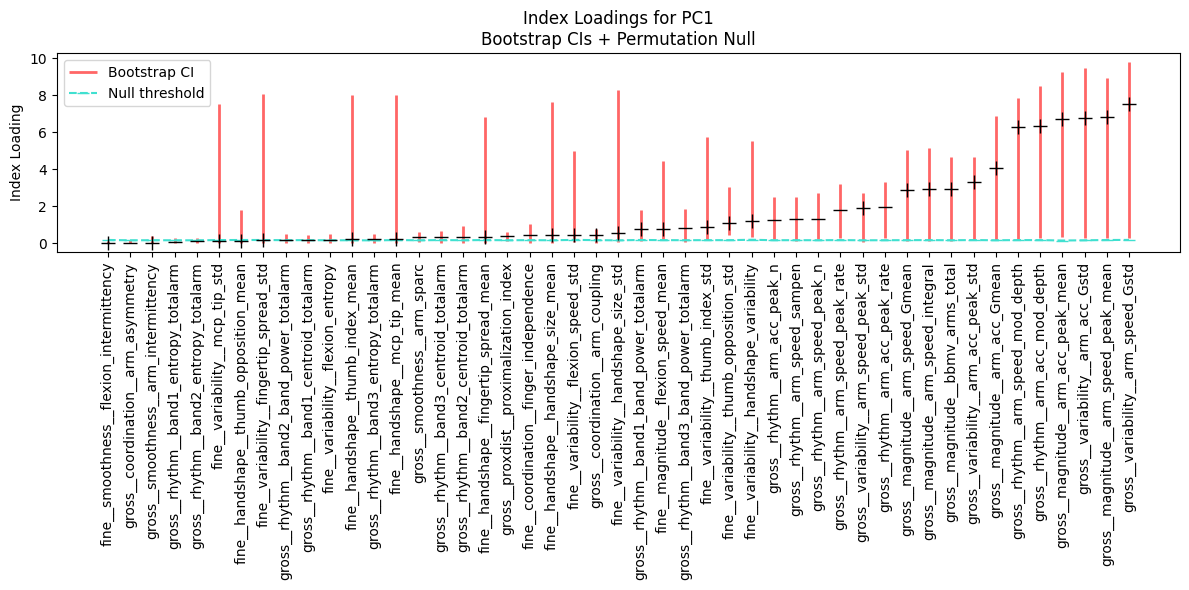

In [39]:
pc_idx = 0  # PC1

# observed
obs_loadings_GS = pca_GS.components_[pc_idx]
obs_eig_GS = pca_GS.explained_variance_[pc_idx]
obs_index_GS = (obs_loadings_GS**2) * (obs_eig_GS**2)

# bootstrap index loadings
boot_index_GS = (bootstrap_results_GS["boot_loadings"][:, :, pc_idx]**2) * (bootstrap_results_GS["boot_eigs"][:, pc_idx][:, None]**2)

boot_low_GS = np.percentile(boot_index_GS, 5, axis=0)
boot_high_GS = np.percentile(boot_index_GS, 95, axis=0)

# null index loadings
null_index_GS = (permutation_results_GS["null_loadings"][:, :, pc_idx]**2) * (permutation_results_GS["null_eigs"][:, pc_idx][:, None]**2)
null_thresh_GS = np.percentile(null_index_GS, 95, axis=0)

df_pc_GS = pd.DataFrame({
    "variable": df_clean.columns[:-1],
    "obs_index": obs_index_GS,
    "boot_low": boot_low_GS,
    "boot_high": boot_high_GS,
    "null_thresh": null_thresh_GS,
    "loading_sign": np.sign(obs_loadings_GS )
})

df_pc_GS = df_pc_GS.sort_values("obs_index")

plot_index_loadings(df_pc_GS, pc_name="PC1")



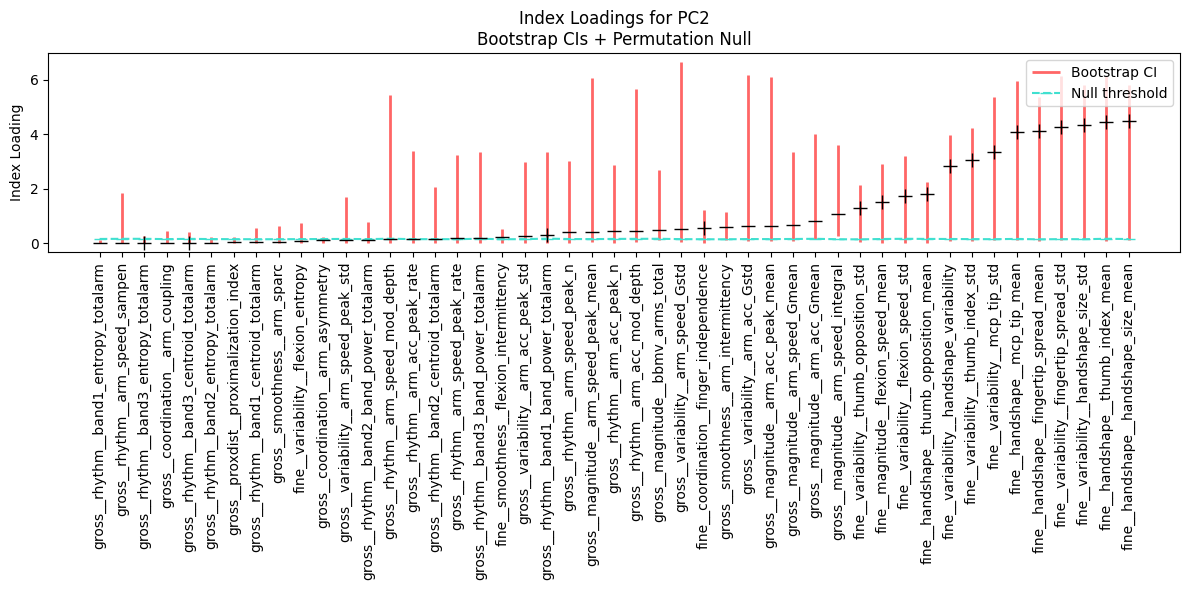

In [40]:
pc_idx = 1  # PC2

# observed
obs_loadings_GS = pca_GS.components_[pc_idx]
obs_eig_GS = pca_GS.explained_variance_[pc_idx]
obs_index_GS = (obs_loadings_GS**2) * (obs_eig_GS**2)

# bootstrap index loadings
boot_index_GS = (bootstrap_results_GS["boot_loadings"][:, :, pc_idx]**2) * (bootstrap_results_GS["boot_eigs"][:, pc_idx][:, None]**2)

boot_low_GS = np.percentile(boot_index_GS, 5, axis=0)
boot_high_GS = np.percentile(boot_index_GS, 95, axis=0)

# null index loadings
null_index_GS = (permutation_results_GS["null_loadings"][:, :, pc_idx]**2) * (permutation_results_GS["null_eigs"][:, pc_idx][:, None]**2)
null_thresh_GS = np.percentile(null_index_GS, 95, axis=0)

df_pc_GS = pd.DataFrame({
    "variable": df_clean.columns[:-1],
    "obs_index": obs_index_GS,
    "boot_low": boot_low_GS,
    "boot_high": boot_high_GS,
    "null_thresh": null_thresh_GS,
    "loading_sign": np.sign(obs_loadings_GS )
})

df_pc_GS = df_pc_GS.sort_values("obs_index")

plot_index_loadings(df_pc_GS, pc_name="PC2")

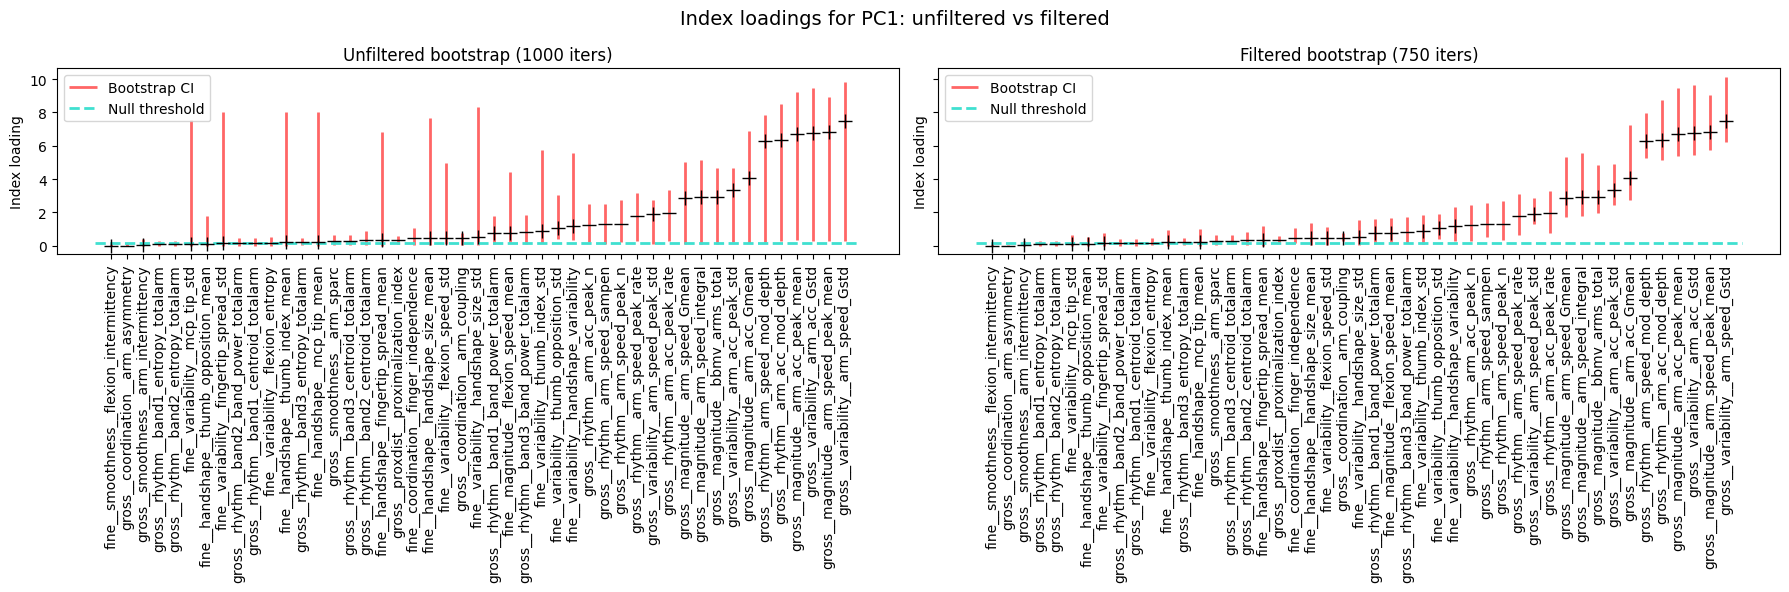

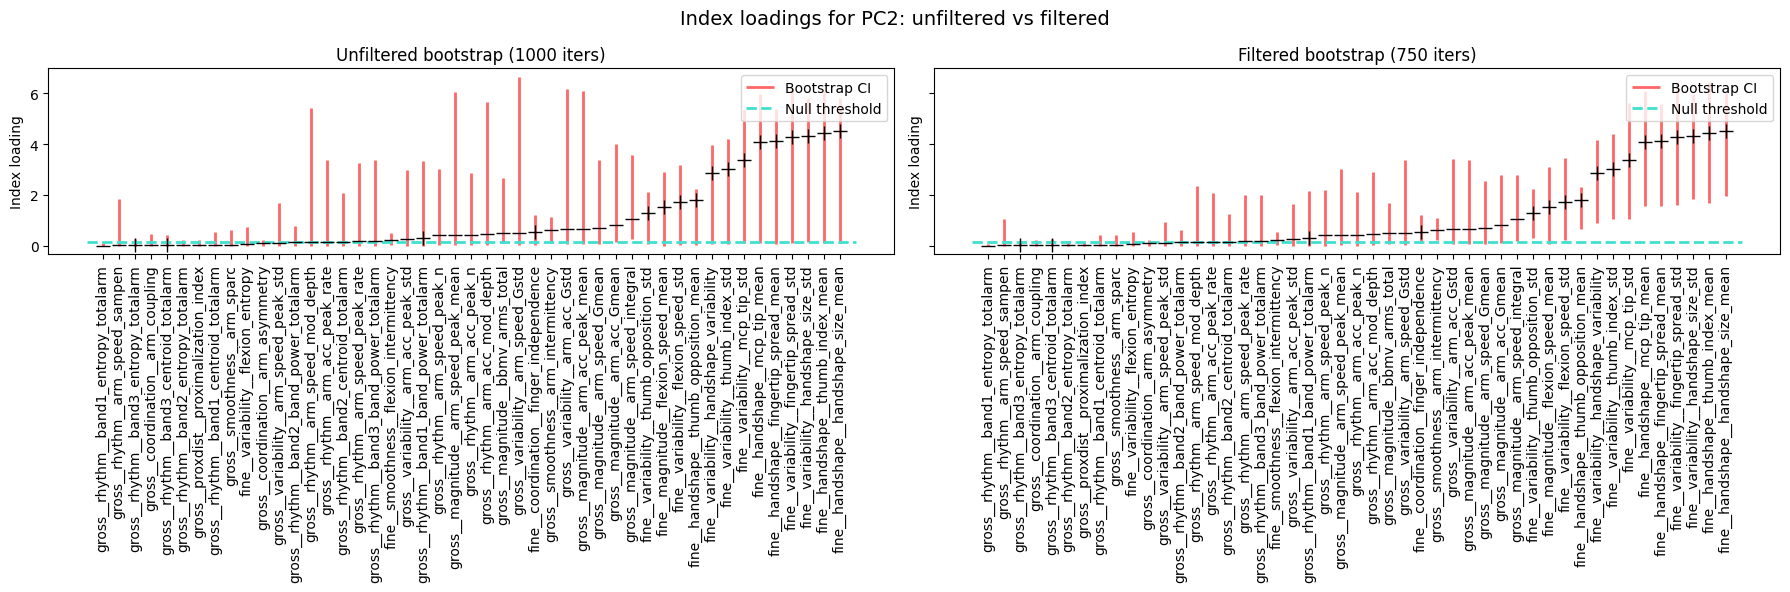

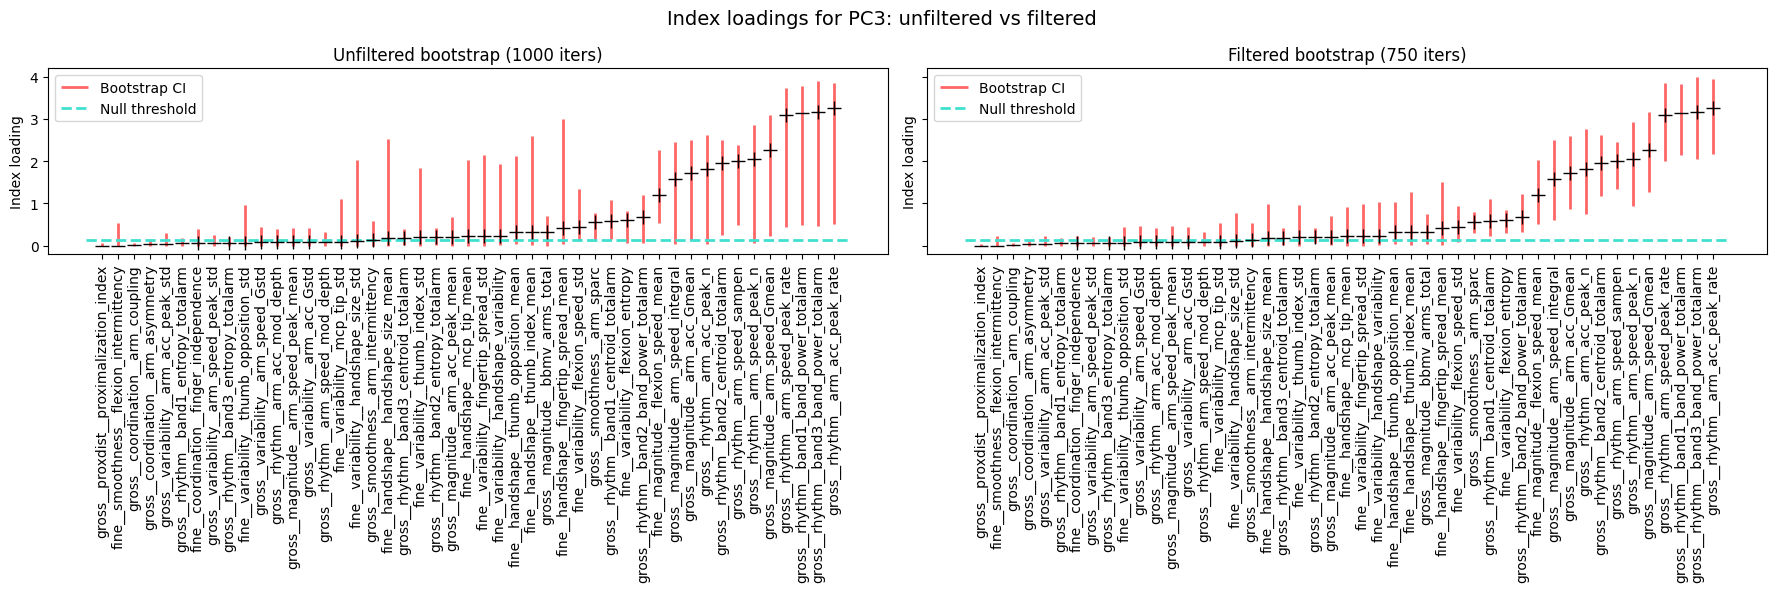

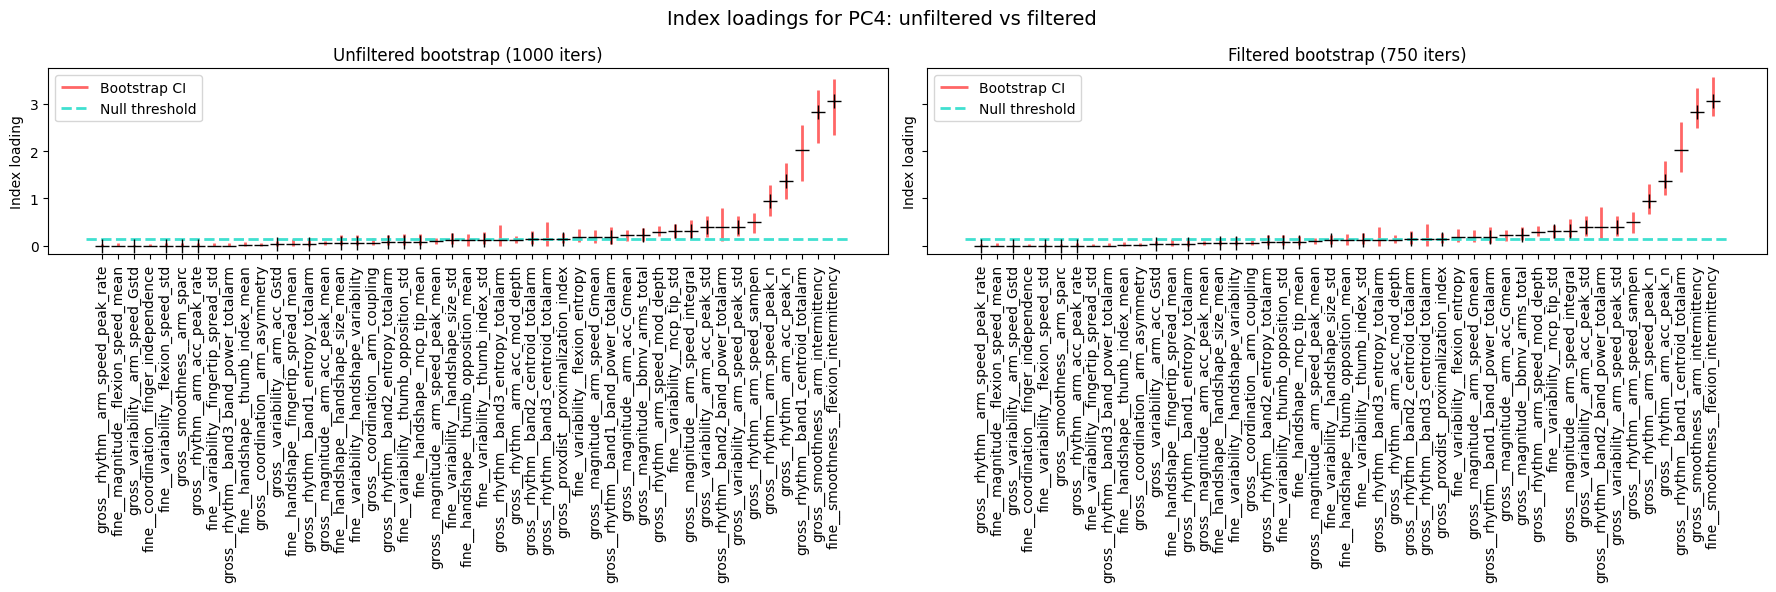

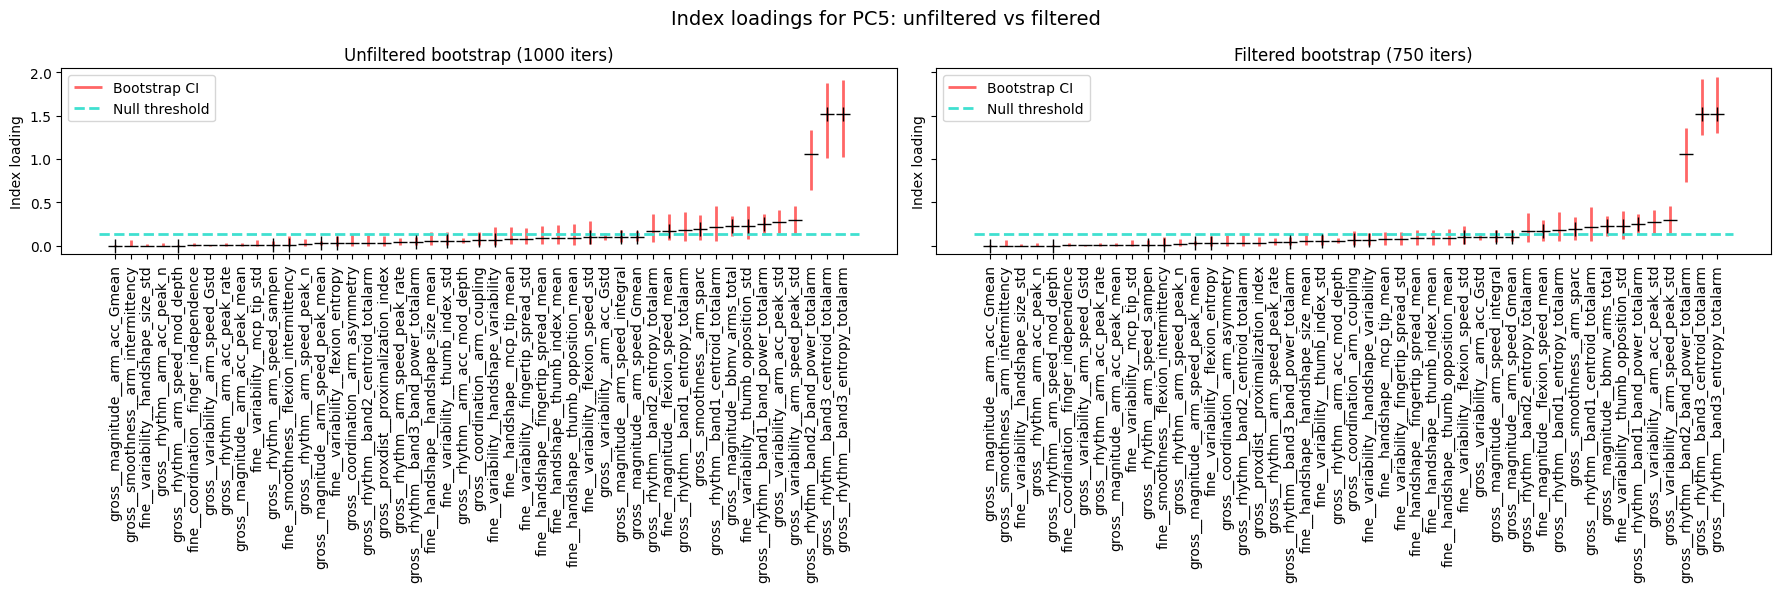

In [41]:
# Compare original vs filtered bootstrap for EVERY significant PC (GS / all groups)
for pc in np.where(sig_pc_GS)[0]:
    plot_loadings_compare(pca_GS, bootstrap_results_GS, permutation_results_GS,
                          pc_idx=int(pc), feature_names=df_clean.columns[:-1],
                          pc_name=f"PC{pc+1}")


In [42]:
def identify_sigvar_filtered(pca, bootstrap_results, permutation_results, feature_names,
                             loadings_confint=0.9, quantile_threshold=0.25, n_pcs=None):
    n_pcs = n_pcs or pca.components_.shape[0]
    out = []
    for pc in range(n_pcs):
        df, n_kept = index_loadings_pc(pca, bootstrap_results, permutation_results, pc,
                                       feature_names, loadings_confint,
                                       filter_boots=True, quantile_threshold=quantile_threshold)
        out.append(df.assign(PC=pc + 1, kept_iterations=n_kept))
    return pd.concat(out, ignore_index=True)


# Compare which variables are "significant" before vs after filtering
df_sig_vars_GS_filt = identify_sigvar_filtered(
    pca_GS, bootstrap_results_GS, permutation_results_GS,
    feature_names=list(df_clean.columns[:-1]), n_pcs=10)

uf = df_sig_vars_GS.rename(columns={"low_confint": "boot_low", "high_confint": "boot_high"})
merged = (uf[["PC", "feature", "sig_loading"]]
          .merge(df_sig_vars_GS_filt[["PC", "variable", "sig_loading", "boot_low", "boot_high"]],
                 left_on=["PC", "feature"], right_on=["PC", "variable"],
                 suffixes=("_unfilt", "_filt")))
changed = merged[merged["sig_loading_unfilt"] != merged["sig_loading_filt"]]
print("Variables whose significance status changes after filtering:")
changed.sort_values(["PC", "feature"])

Variables whose significance status changes after filtering:


,PC,feature,sig_loading_unfilt,variable,sig_loading_filt,boot_low,boot_high


50% cumulative contribution

In [43]:
def top_until_50pct(index_loadings_pc, feature_names):
    total = index_loadings_pc.sum()
    df = pd.DataFrame({
        "feature": feature_names,
        "index_loading": index_loadings_pc
    }).sort_values("index_loading", ascending=False)
    
    df["cum_frac"] = df["index_loading"].cumsum() / total
    return df[df["cum_frac"] <= 0.5]

# Example for PC1
index_loadings_GS = (pca_GS.components_.T ** 2) * (pca_GS.explained_variance_ ** 2)
top_pc1 = top_until_50pct(index_loadings_GS[:, 0], df_clean.columns[:-1])
top_pc1


,feature,index_loading,cum_frac
1,gross__variability__arm_speed_Gstd,7.514247,0.097169
2,gross__magnitude__arm_speed_peak_mean,6.854520,0.185808
8,gross__variability__arm_acc_Gstd,6.791728,0.273634
9,gross__magnitude__arm_acc_peak_mean,6.731515,0.360682
13,gross__rhythm__arm_acc_mod_depth,6.342597,0.442700


## Plot only significant vars

### Biplot PC1-PC2

Figure saved to: g:\GtST_FLESH_KinTrajectory\Plots\PCA_GS_all_PC1_2_biplot.png


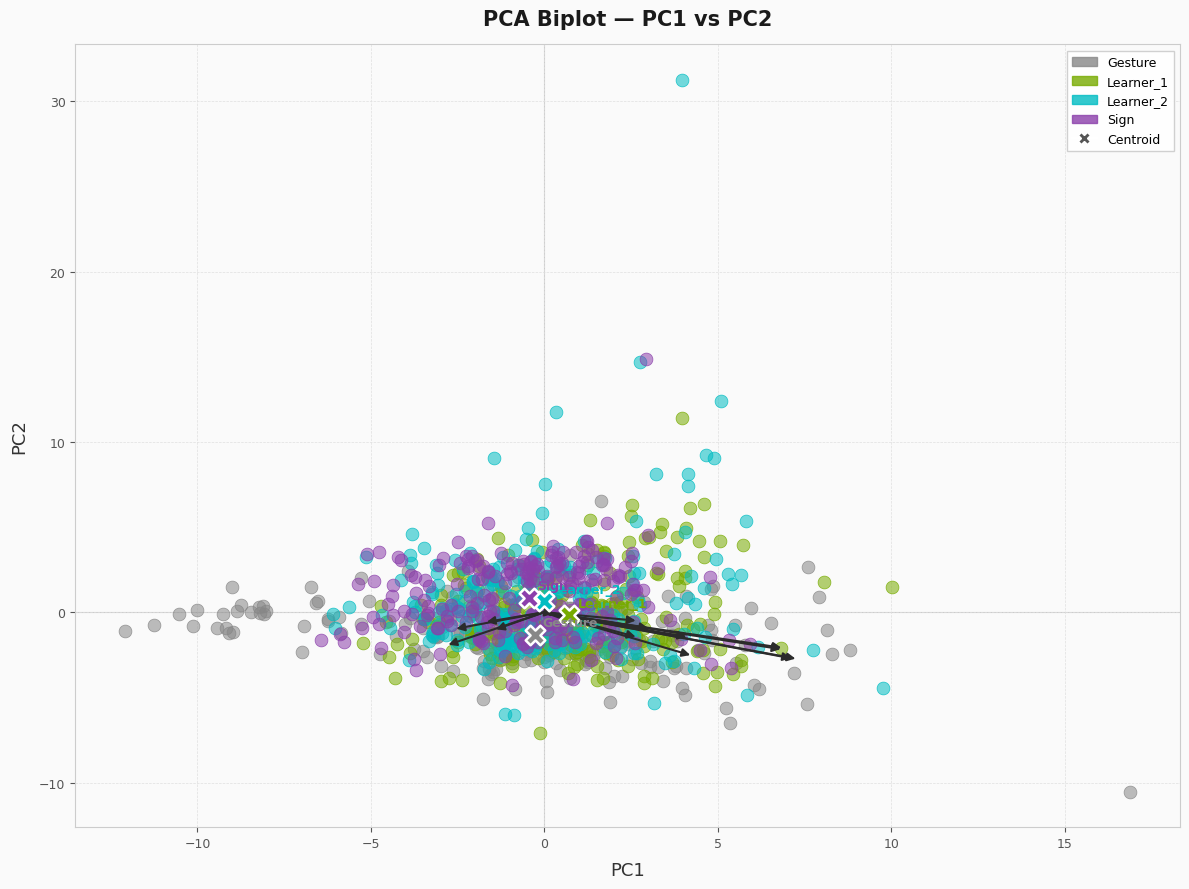

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC2'}, xlabel='PC1', ylabel='PC2'>)

In [82]:
pcs_to_plot = [1, 2]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin([1,2])]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=1, pc_y=2,
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=1, pc_y=2,
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "Plots", "PCA_GS_all_PC1_2_biplot.png")
)

### Biplot PC2-PC3

Figure saved to: g:\GtST_FLESH_KinTrajectory\Plots\PCA_GS_all_PC2_3_biplot.png


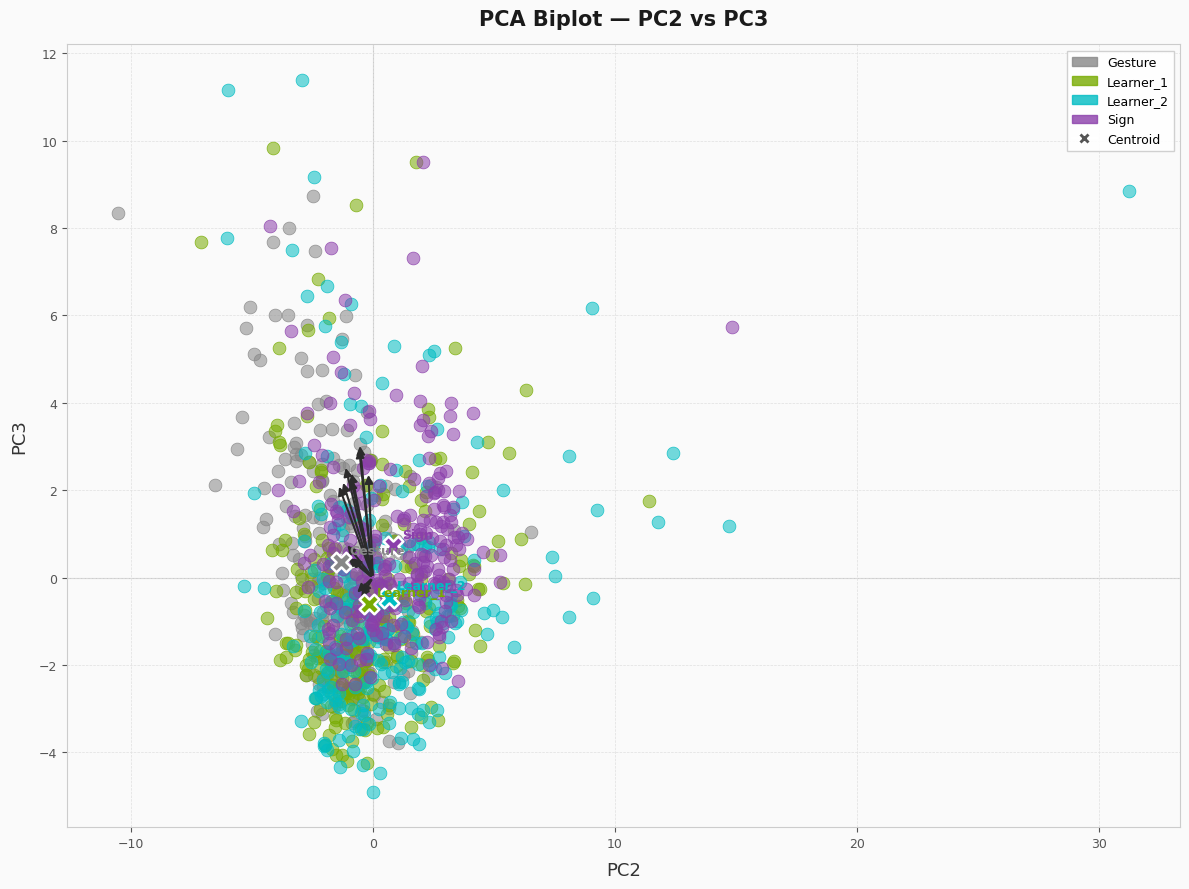

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC2 vs PC3'}, xlabel='PC2', ylabel='PC3'>)

In [83]:
pcs_to_plot = [2, 3]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin([pcs_to_plot])]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "Plots", "PCA_GS_all_PC2_3_biplot.png")
)


### Biplot PC1-PC3

Figure saved to: g:\GtST_FLESH_KinTrajectory\Plots\PCA_GS_all_PC1_3_biplot.png


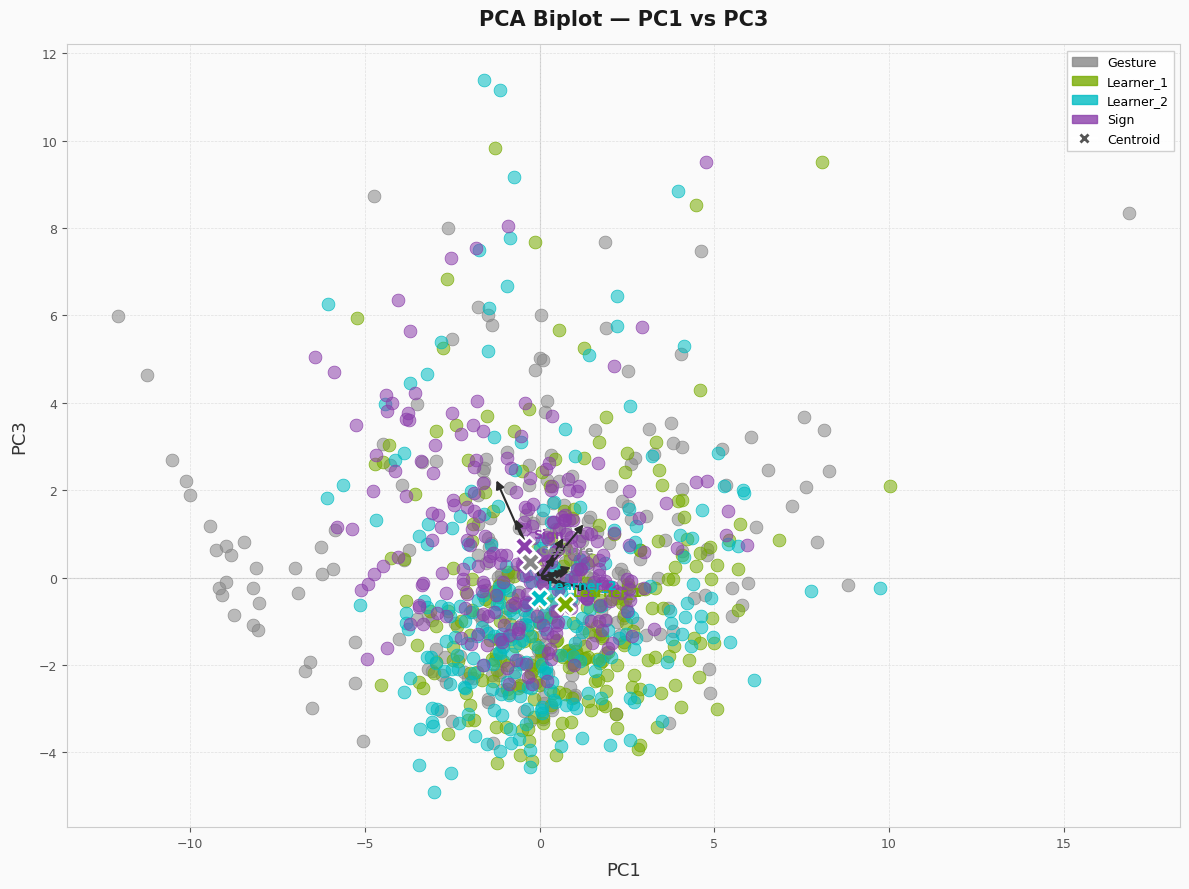

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC3'}, xlabel='PC1', ylabel='PC3'>)

In [84]:
pcs_to_plot = [1, 3]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "Plots", "PCA_GS_all_PC1_3_biplot.png")
)

### Biplot PC1-PC4

Figure saved to: g:\GtST_FLESH_KinTrajectory\Plots\PCA_GS_all_PC1_4_biplot.png


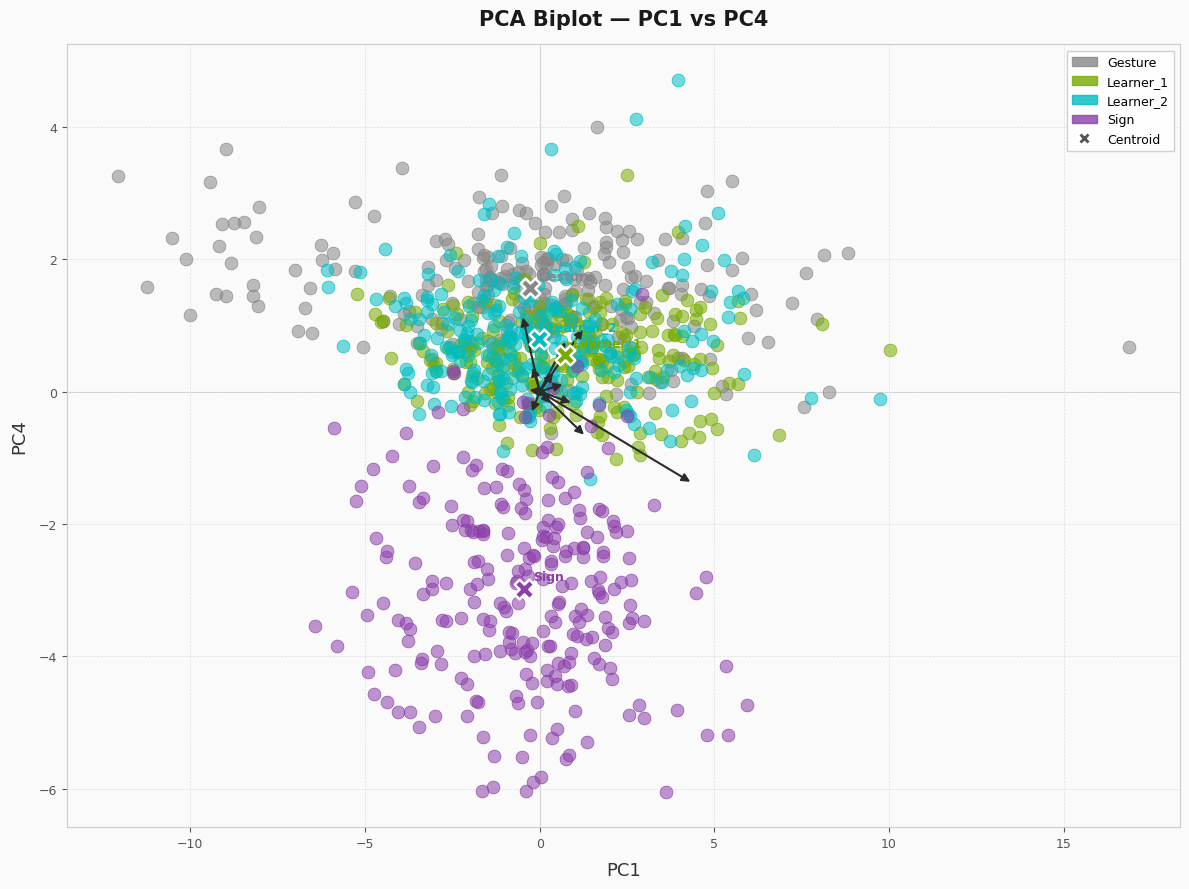

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC4'}, xlabel='PC1', ylabel='PC4'>)

In [85]:
pcs_to_plot = [1, 4]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "Plots", "PCA_GS_all_PC1_4_biplot.png")
)

### Biplot PC2-PC4

Figure saved to: g:\GtST_FLESH_KinTrajectory\Plots\PCA_GS_all_PC1_4_biplot.png


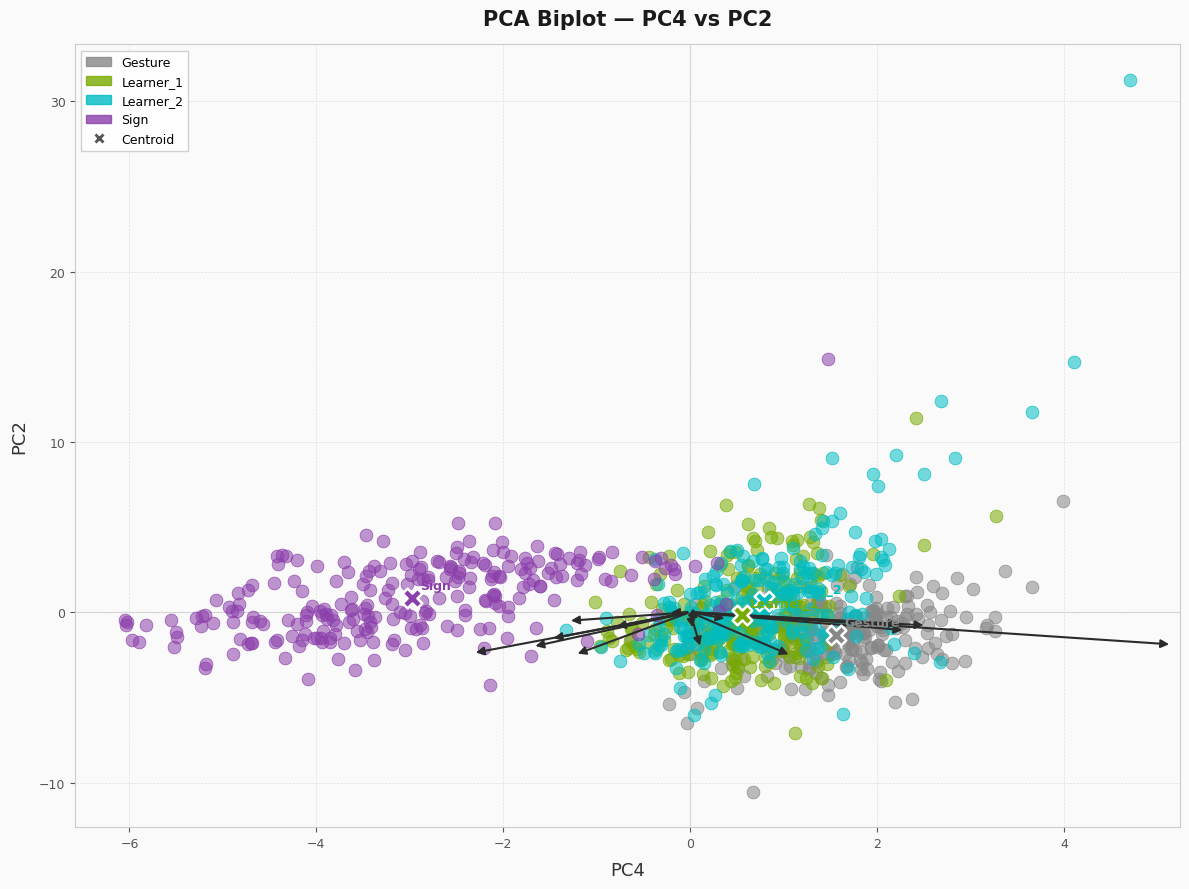

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC4 vs PC2'}, xlabel='PC4', ylabel='PC2'>)

In [81]:
pcs_to_plot = [4, 2]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "Plots", "PCA_GS_all_PC1_4_biplot.png")
)

### Biplot PC1-PC5

Figure saved to: g:\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC1_5_biplot.png


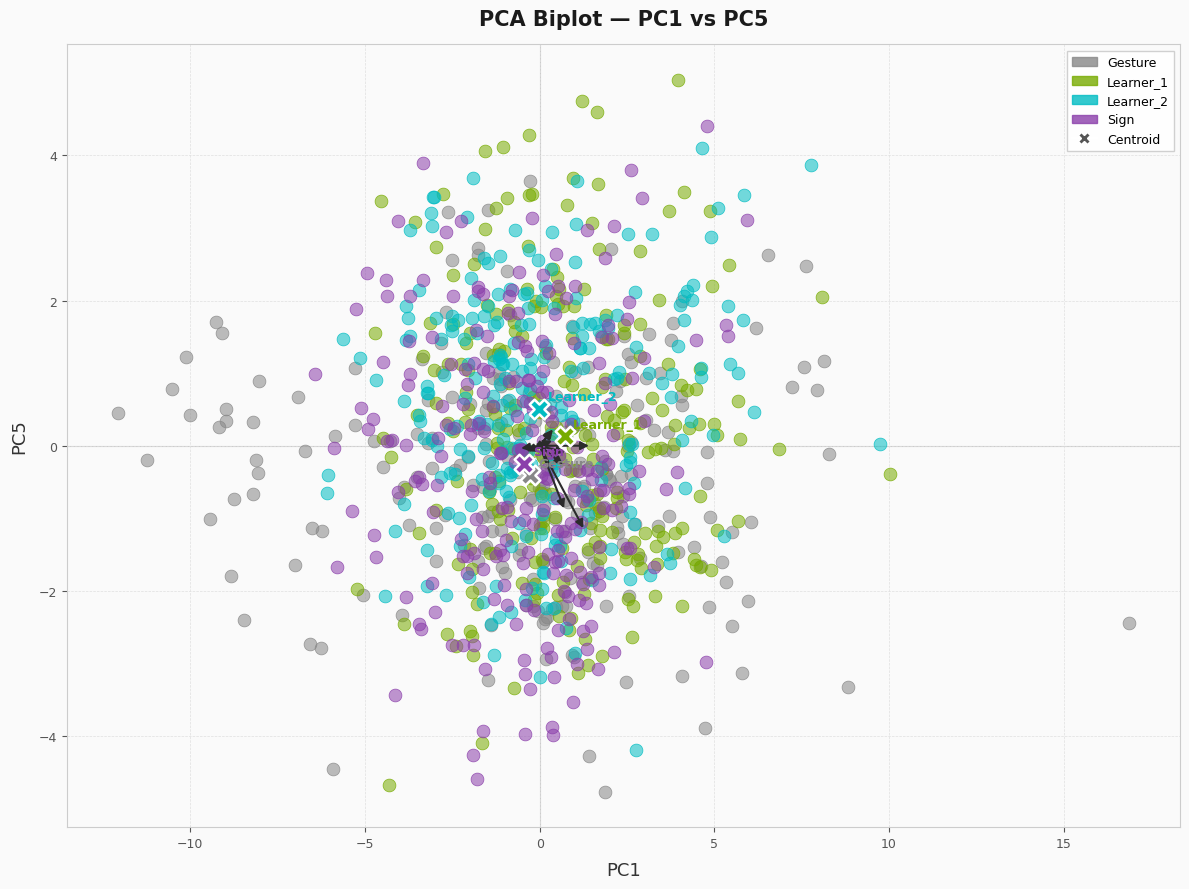

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC5'}, xlabel='PC1', ylabel='PC5'>)

In [86]:
pcs_to_plot = [1, 5]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC1_5_biplot.png")
)


### Biplot PC4-PC5 

Figure saved to: g:\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC4_5_biplot.png


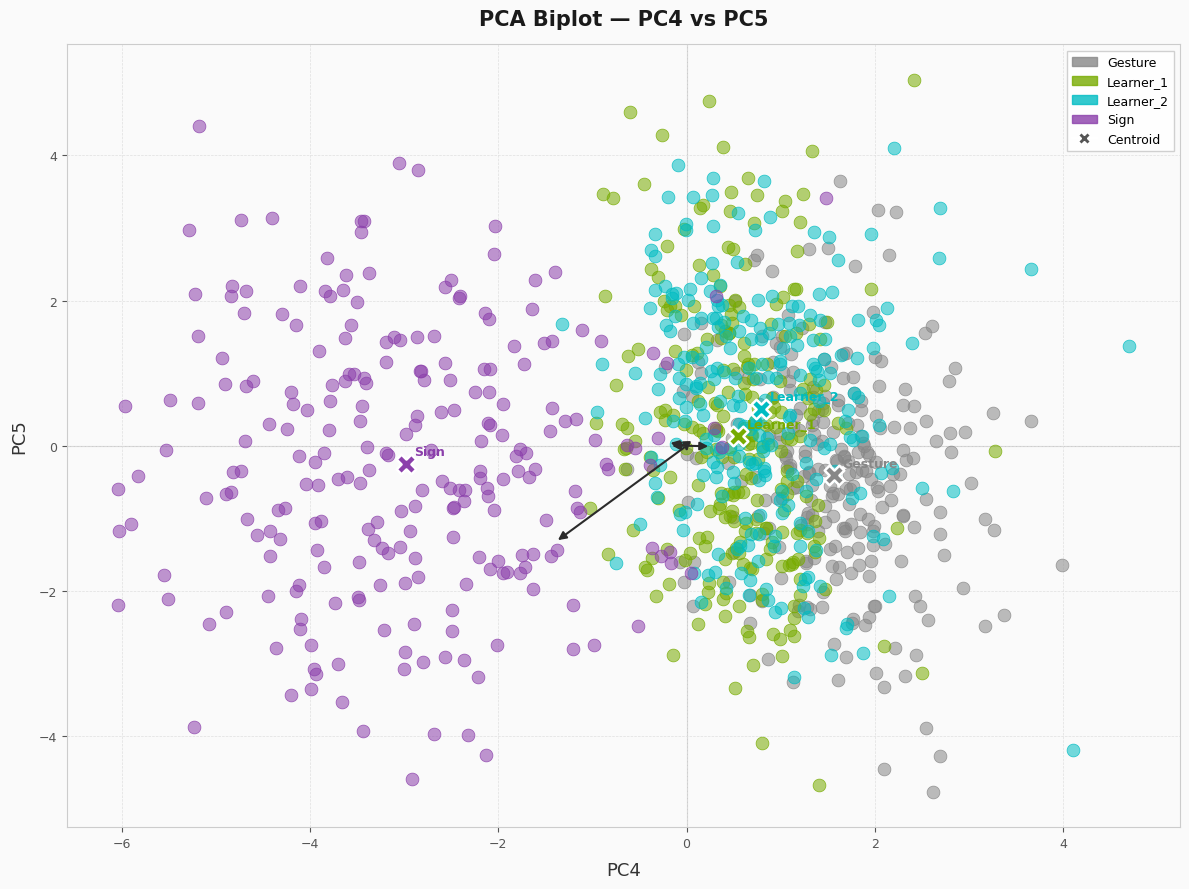

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC4 vs PC5'}, xlabel='PC4', ylabel='PC5'>)

In [87]:
pcs_to_plot = [4, 5]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    le=le,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC4_5_biplot.png")
)


### 3D plot

In [50]:
def interactive_PCA_biplot_3D(score, coeff, labels=None, y=None, selected_vars=None,
                               arrow_strength=None, pc_x=1, pc_y=2, pc_z=3,
                               show_labels=True, concepts=None,
                               highlight_concepts=None, le=None):
    ix, iy, iz = pc_x - 1, pc_y - 1, pc_z - 1
    xs, ys, zs = score[:, ix], score[:, iy], score[:, iz]
    concepts = np.array(concepts) if concepts is not None else None

    if concepts is not None and len(concepts) != len(xs):
        print(f"Warning: concepts length ({len(concepts)}) doesn't match score rows ({len(xs)}). Ignoring concepts.")
        concepts = None

    def group_name(g):
        return le.inverse_transform([g])[0] if le is not None else f"Group {g}"

    # --- Discrete color mapping per group ---
    groups = np.unique(y)
    palette = [
        '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
        '#9467bd', '#8c564b', '#e377c2', '#7f7f7f'
    ]
    color_map = {g: palette[i % len(palette)] for i, g in enumerate(groups)}

    traces = []

    # --- One scatter trace per group ---
    for g in groups:
        mask = y == g
        traces.append(go.Scatter3d(
            x=xs[mask], y=ys[mask], z=zs[mask],
            mode='markers',
            marker=dict(size=5, color=color_map[g], opacity=0.7),
            name=group_name(g),
            text=[group_name(g) + (f"<br>{concepts[i]}" if concepts is not None else "")
                  for i in np.where(mask)[0]],
            hoverinfo='text',
            showlegend=True
        ))

    # --- Highlighted concept overlays ---
    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            mask = np.where(concepts == concept)[0]

            seen_groups = {}
            for idx in mask:
                group = y[idx]
                if group not in seen_groups:
                    seen_groups[group] = idx

            representative_indices = list(seen_groups.values())

            traces.append(go.Scatter3d(
                x=xs[representative_indices],
                y=ys[representative_indices],
                z=zs[representative_indices],
                mode='markers',
                marker=dict(size=10, color='red', symbol='diamond',
                            line=dict(color='black', width=1)),
                name=concept,
                text=[f"{concept} — {group_name(y[i])}" for i in representative_indices],
                hoverinfo='text',
                showlegend=True
            ))

    # Arrows
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    arrow_scale = 10

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        scale = arrow_scale * (arrow_strength.get(var_name, 1.0) if arrow_strength else 1.0)

        # Arrow line
        traces.append(go.Scatter3d(
            x=[0, coeff[i, ix] * scale],
            y=[0, coeff[i, iy] * scale],
            z=[0, coeff[i, iz] * scale],
            mode='lines+markers+text' if show_labels else 'lines+markers',
            line=dict(color='black', width=3),
            marker=dict(size=3, color='black'),
            text=[None, var_name] if show_labels else None,
            textposition='top center',
            hovertext=var_name,
            hoverinfo='text',
            showlegend=False
        ))

    layout = go.Layout(
        title=f"Interactive 3D PCA Biplot — PC{pc_x} vs PC{pc_y} vs PC{pc_z}",
        scene=dict(
            xaxis_title=f"PC{pc_x}",
            yaxis_title=f"PC{pc_y}",
            zaxis_title=f"PC{pc_z}",
        ),
        width=900, height=700,
    )

    go.Figure(data=traces, layout=layout).show()

In [51]:
pcs_to_plot = [2, 3, 4]

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

# Map feature names to column indices
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

interactive_PCA_biplot_3D(
    score=x_new_GS,
    coeff=loadings_GS,
    labels=feature_names,
    y=y,
    selected_vars=selected_vars,
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1], pc_z=pcs_to_plot[2],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

## Save features

In [52]:
def select_features_for_pc(pca, bootstrap_results, permutation_results, feature_names,
                           pc_idx, loadings_confint=0.9, quantile_threshold=0.25,
                           verbose=True):
    """Which variables stay in a PC for modelling, accounting for filter_boots.
    keep = significant (obs > null) AND stable after filtering (filtered boot_low > null)."""
    fn = list(feature_names)
    df_uf, _   = index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                                   fn, loadings_confint, filter_boots=False)
    df_fl, n_k = index_loadings_pc(pca, bootstrap_results, permutation_results, pc_idx,
                                   fn, loadings_confint, filter_boots=True,
                                   quantile_threshold=quantile_threshold)
    # anchor = the variable the filter selects on (highest median bootstrap index loading)
    bl = bootstrap_results["boot_loadings"][:, :, pc_idx]
    be = bootstrap_results["boot_eigs"][:, pc_idx][:, None]
    boot_index = (bl ** 2) * (be ** 2)
    winner = fn[int(np.argmax(np.median(boot_index, axis=0)))]

    tbl = (df_uf.rename(columns={"boot_low": "boot_low_unfilt", "boot_high": "boot_high_unfilt"})
           .merge(df_fl.rename(columns={"boot_low": "boot_low_filt",
                                        "boot_high": "boot_high_filt"})
                        [["variable", "boot_low_filt", "boot_high_filt"]], on="variable"))
    tbl["sig_obs"]       = tbl["obs_index"]       > tbl["null_thresh"]   # exclusion rule
    tbl["stable_unfilt"] = tbl["boot_low_unfilt"] > tbl["null_thresh"]
    tbl["stable_filt"]   = tbl["boot_low_filt"]   > tbl["null_thresh"]   # survives stabilisation
    tbl["is_anchor"]     = tbl["variable"] == winner
    tbl["keep"]          = tbl["sig_obs"] & tbl["stable_filt"]
    tbl = tbl.sort_values("obs_index", ascending=False).reset_index(drop=True)
    tbl["share"]        = tbl["obs_index"] / tbl["obs_index"].sum()
    # cumulative share of this PC's total index loading (over ALL features), largest first
    tbl["cum_frac"]     = tbl["obs_index"].cumsum() / tbl["obs_index"].sum()
    tbl["within_50pct"] = tbl["cum_frac"] <= 0.5
    keep = tbl.loc[tbl["keep"], "variable"].tolist()
    if verbose:
        print(f"PC{pc_idx+1}: filtered {n_k} iters | anchor={winner} | "
              f"sig(obs>null)={tbl['sig_obs'].sum()} | keep(sig & stable_filt)={len(keep)}")
    return tbl, keep

In [53]:
# Build the per-PC table for every significant PC, keep ALL significant features,
# and record CI-vs-null status before and after stabilization.
sig_pcs = np.where(sig_pc_GS)[0]                      # 0-based significant PC indices
tables = []
for pc in sig_pcs:
    tbl, _ = select_features_for_pc(pca_GS, bootstrap_results_GS, permutation_results_GS,
                                    df_clean.columns[:-1], pc_idx=pc, verbose=False)
    tables.append(tbl.assign(PC=pc + 1))

sig_features_GS = pd.concat(tables, ignore_index=True)

# keep only significant loadings (your current criterion), rename for a clean file
sig_features_GS = (sig_features_GS[sig_features_GS["sig_obs"]]
                   .rename(columns={"stable_unfilt": "CI_above_null_before",
                                    "stable_filt":   "CI_above_null_after"})
                   [["PC", "variable", "loading_sign", "obs_index",
                     "null_thresh",
                     "boot_low_unfilt", "boot_high_unfilt",
                     "boot_low_filt",  "boot_high_filt",
                     "CI_above_null_before", "CI_above_null_after",
                     "is_anchor", "share",
                      "cum_frac", "within_50pct"]]
                   .sort_values(["PC", "obs_index"], ascending=[True, False])
                   .reset_index(drop=True))

sig_features_GS.to_csv(os.path.join("Datasets", "loadings_all.csv"), index=False)
sig_features_GS

,PC,variable,loading_sign,obs_index,null_thresh,boot_low_unfilt,boot_high_unfilt,boot_low_filt,boot_high_filt,CI_above_null_before,CI_above_null_after,is_anchor,share,cum_frac,within_50pct
0,1,gross__variability__arm_speed_Gstd,1.0,7.514247,0.172881,0.279582,9.797834,6.229617,10.140298,True,True,True,0.097169,0.097169,True
1,1,gross__magnitude__arm_speed_peak_mean,1.0,6.854520,0.168061,0.271295,8.940949,5.741992,9.075593,True,True,False,0.088638,0.185808,True
2,1,gross__variability__arm_acc_Gstd,1.0,6.791728,0.152141,0.297578,9.460140,5.420061,9.656529,True,True,False,0.087826,0.273634,True
3,1,gross__magnitude__arm_acc_peak_mean,1.0,6.731515,0.141194,0.334646,9.242103,5.406618,9.466000,True,True,False,0.087048,0.360682,True
4,1,gross__rhythm__arm_acc_mod_depth,1.0,6.342597,0.162229,0.257979,8.521878,5.171354,8.717344,True,True,False,0.082018,0.442700,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,5,gross__rhythm__band1_centroid_totalarm,-1.0,0.216026,0.133136,0.050163,0.452518,0.057641,0.450605,False,False,False,0.027878,0.720679,False
126,5,gross__smoothness__arm_sparc,1.0,0.187089,0.142412,0.068355,0.358466,0.060250,0.328144,False,False,False,0.024144,0.744823,False
127,5,gross__rhythm__band1_entropy_totalarm,-1.0,0.185312,0.120463,0.053569,0.384725,0.052245,0.391738,False,False,False,0.023915,0.768737,False
128,5,fine__magnitude__flexion_speed_mean,1.0,0.174317,0.142507,0.063269,0.366244,0.058481,0.301307,False,False,False,0.022496,0.791233,False


# PCA: All groups (gross only)

In [54]:
# read it
df_clean = pd.read_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'))

In [55]:
# get rid of all columns with fine_ in the name
cols_to_drop = [col for col in df_clean.columns if col.startswith('fine_')]
df_clean = df_clean.drop(columns=cols_to_drop)

In [56]:
feature_names = df_clean.columns[:-1].to_list()

# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features

df_clean['groupID'] = df_clean['groupID'].astype('category')
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler_GSG = StandardScaler()
Xz_GSG = scaler_GSG.fit_transform(X)    

# PCA transformation
pca_GSG = PCA()
x_new_GSG = pca_GSG.fit_transform(Xz_GSG)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings_GSG = pca_GSG.components_.T

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # PC1 and PC2 (the PCs you plot below)
    component = loadings_GSG[:, i]      # column i = all variables' loadings ON PC i
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(score=x_new_GSG, 
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                       le=le,
                        arrow_strength=arrow_strength                    )

In [57]:
# PC2-3
interactive_PCA_biplot(score=x_new_GSG,
                          coeff=loadings_GSG, 
                          labels=feature_names, 
                          y=y, 
                          selected_vars=selected_vars, 
                          pc_x=2, pc_y=3,
                          show_labels=False,
                          le=le,
                            arrow_strength=arrow_strength                      )

Figure saved to: g:\GtST_FLESH_KinTrajectory\plots\PCA_GSG_PC1_2_biplot.png


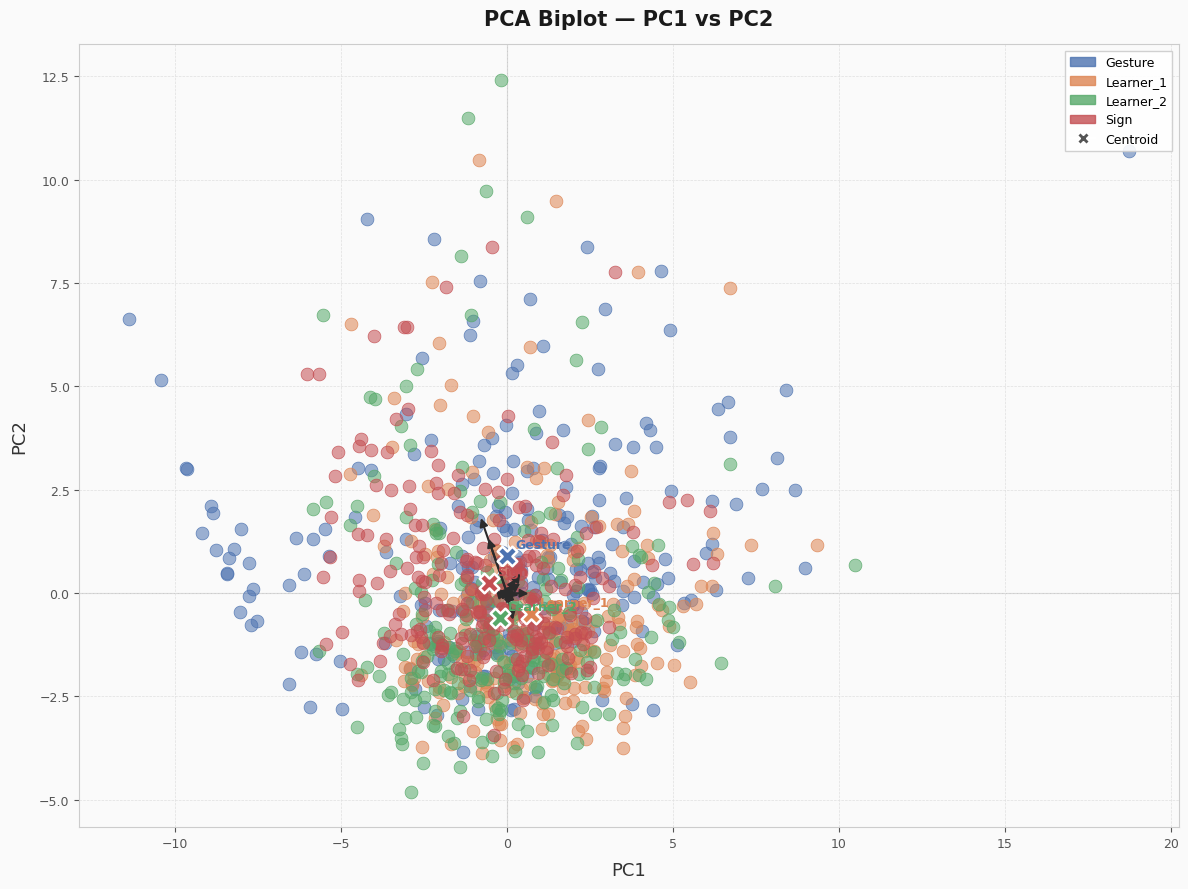

Figure saved to: g:\GtST_FLESH_KinTrajectory\plots\PCA_GSG_PC2_3_biplot.png


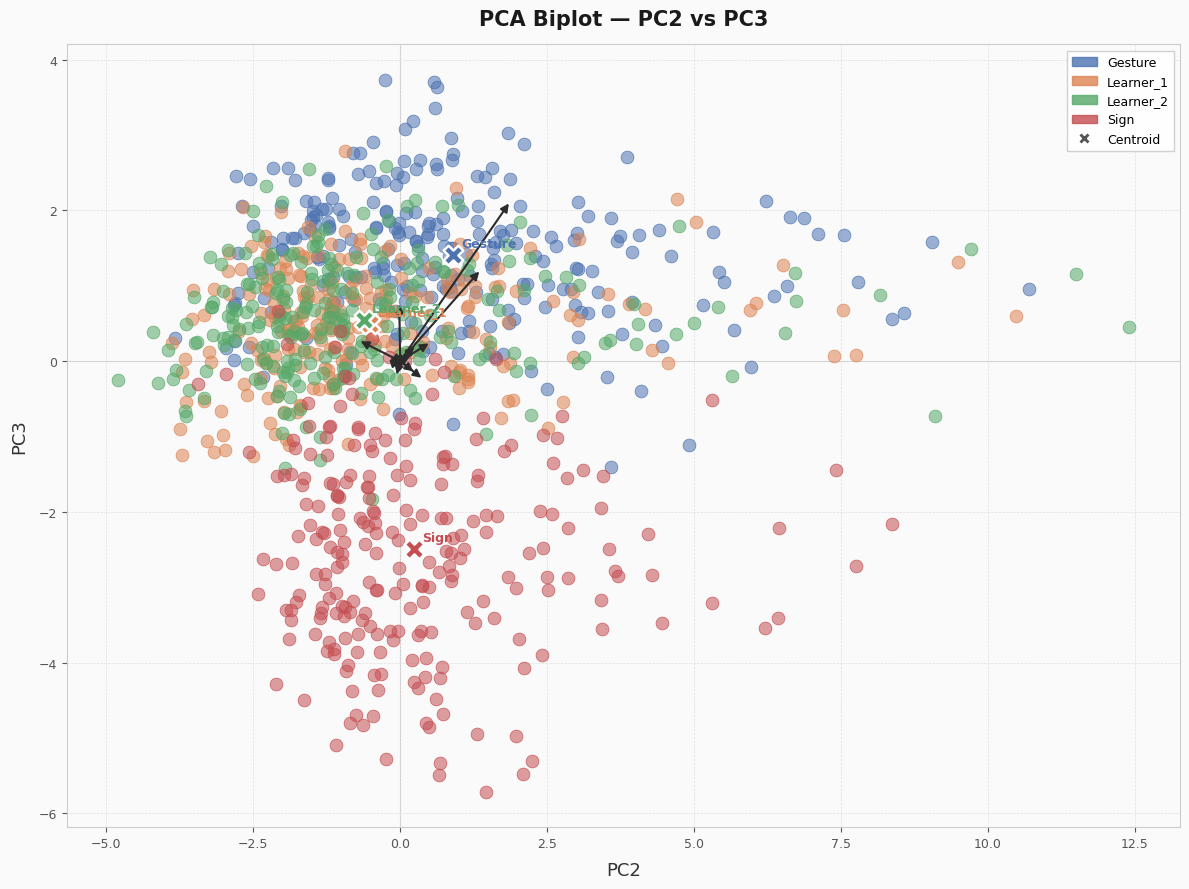

Figure saved to: g:\GtST_FLESH_KinTrajectory\plots\PCA_GSG_PC3_4_biplot.png


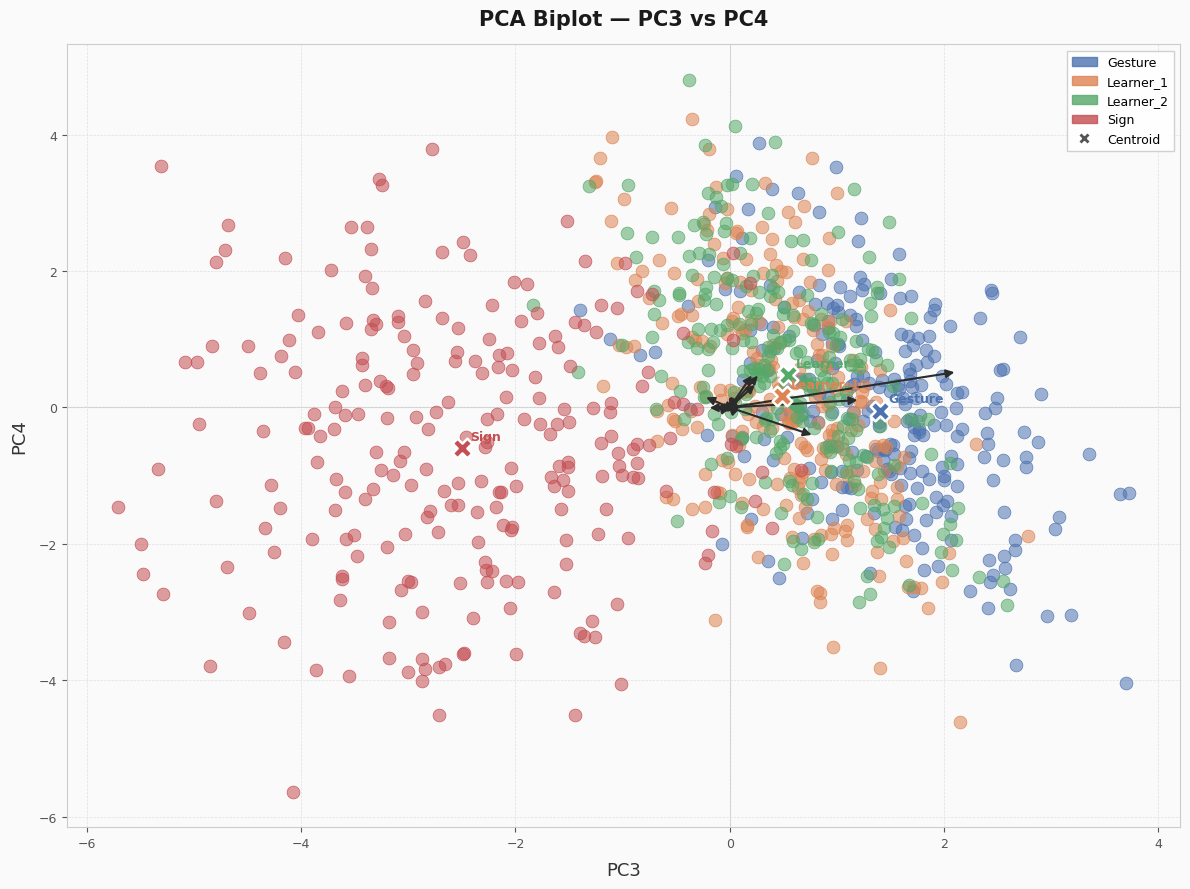

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC3 vs PC4'}, xlabel='PC3', ylabel='PC4'>)

In [58]:
# static 1-2
static_PCA_biplot(score=x_new_GSG, 
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                        arrow_strength=arrow_strength,
                        le=le,
                       save_path=os.path.join(curfolder, "plots", "PCA_GSG_PC1_2_biplot.png")
                    )

# static 2-3
static_PCA_biplot(score=x_new_GSG,
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=2, pc_y=3,
                       show_labels=False,
                        arrow_strength=arrow_strength,
                        le=le,
                       save_path=os.path.join(curfolder, "plots", "PCA_GSG_PC2_3_biplot.png")
                    )

# 3-4
static_PCA_biplot(score=x_new_GSG,
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=3, pc_y=4,
                       show_labels=False,
                        arrow_strength=arrow_strength,
                        le=le,
                       save_path=os.path.join(curfolder, "plots", "PCA_GSG_PC3_4_biplot.png")
                    )

## Bootstraping and significance

In [59]:
bootstrap_results_GSG = bootstrap_pca(Xz_GSG)
permutation_results_GSG = permutation_pca(Xz_GSG)

# determine significant PCs
var_explained_GSG = pca_GSG.explained_variance_ratio_
null_var_thresh_GSG = permutation_results_GSG["null_eig_thresh"] / np.sum(pca_GSG.explained_variance_)  # convert eig to variance ratio
sig_pc_null_GSG = var_explained_GSG > null_var_thresh_GSG

# apply 5-10 % cut-off
sig_pc_effect_GSG = var_explained_GSG > 0.05  # 5% cut-off
sig_pc_GSG = sig_pc_null_GSG & sig_pc_effect_GSG

print("Significant PCs:")
for i, sig in enumerate(sig_pc_GSG, start=1):
    print(f"PC{i}: significant = {sig}, var explained = {var_explained_GSG[i-1]:.3f}")

Significant PCs:
PC1: significant = True, var explained = 0.273
PC2: significant = True, var explained = 0.187
PC3: significant = True, var explained = 0.098
PC4: significant = True, var explained = 0.085
PC5: significant = True, var explained = 0.053
PC6: significant = False, var explained = 0.046
PC7: significant = False, var explained = 0.039
PC8: significant = False, var explained = 0.034
PC9: significant = False, var explained = 0.029
PC10: significant = False, var explained = 0.028
PC11: significant = False, var explained = 0.024
PC12: significant = False, var explained = 0.020
PC13: significant = False, var explained = 0.020
PC14: significant = False, var explained = 0.015
PC15: significant = False, var explained = 0.011
PC16: significant = False, var explained = 0.009
PC17: significant = False, var explained = 0.007
PC18: significant = False, var explained = 0.005
PC19: significant = False, var explained = 0.005
PC20: significant = False, var explained = 0.004
PC21: significant

## Identify sig variables

In [60]:
df_sig_vars_GSG = identify_sigvar(pca_GSG, bootstrap_results_GSG, permutation_results_GSG, df_clean)
df_sig_vars_GSG[df_sig_vars_GSG["sig_loading"]].sort_values(["PC", "index_loading"], ascending=[True, False])

,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
1,1,gross__variability__arm_speed_Gstd,0.328223,7.740969,5.918510,9.886870,0.000274,0.198627,True
8,1,gross__variability__arm_acc_Gstd,0.316060,7.177856,5.263178,9.542000,0.000309,0.197866,True
9,1,gross__magnitude__arm_acc_peak_mean,0.315248,7.141022,5.268991,9.367694,0.000434,0.231052,True
2,1,gross__magnitude__arm_speed_peak_mean,0.313940,7.081914,5.430927,8.898426,0.000332,0.206784,True
13,1,gross__rhythm__arm_acc_mod_depth,0.305302,6.697538,5.115737,8.619092,0.000319,0.206390,True
...,...,...,...,...,...,...,...,...,...
234,8,gross__smoothness__arm_sparc,0.380597,0.163997,0.008423,0.349276,0.000242,0.160523,True
268,9,gross__rhythm__band1_entropy_totalarm,0.481876,0.189226,0.001522,0.448210,0.000194,0.158787,True
251,9,gross__variability__arm_speed_peak_std,-0.457166,0.170317,0.005431,0.204753,0.000203,0.142889,True
299,10,gross__rhythm__band1_entropy_totalarm,0.584854,0.252499,0.004712,0.378372,0.000142,0.135903,True


In [61]:
sig_idx = np.where(sig_pc_GSG)[0]                       # significant PCs (null AND >=5%)
pc_cols = [f"PC{i+1}" for i in sig_idx]
scores  = pd.DataFrame(x_new_GSG[:, sig_idx], columns=pc_cols)

meta = (sampled_df[['group', 'groupID', 'concept']]
        .reset_index(drop=True)
        .rename(columns={'group': 'participant'}))
assert len(meta) == len(scores), "row mismatch — metadata not aligned with PCA scores!"

out = pd.concat([scores, meta], axis=1)
for row in out.itertuples():
    if row.participant.startswith('IP'):
        out.loc[row.Index, 'participant'] = row.participant.split('_')[0]

out.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_gross.csv'), index=False)

## Filtered vs unfiltered loadings (per significant PC)

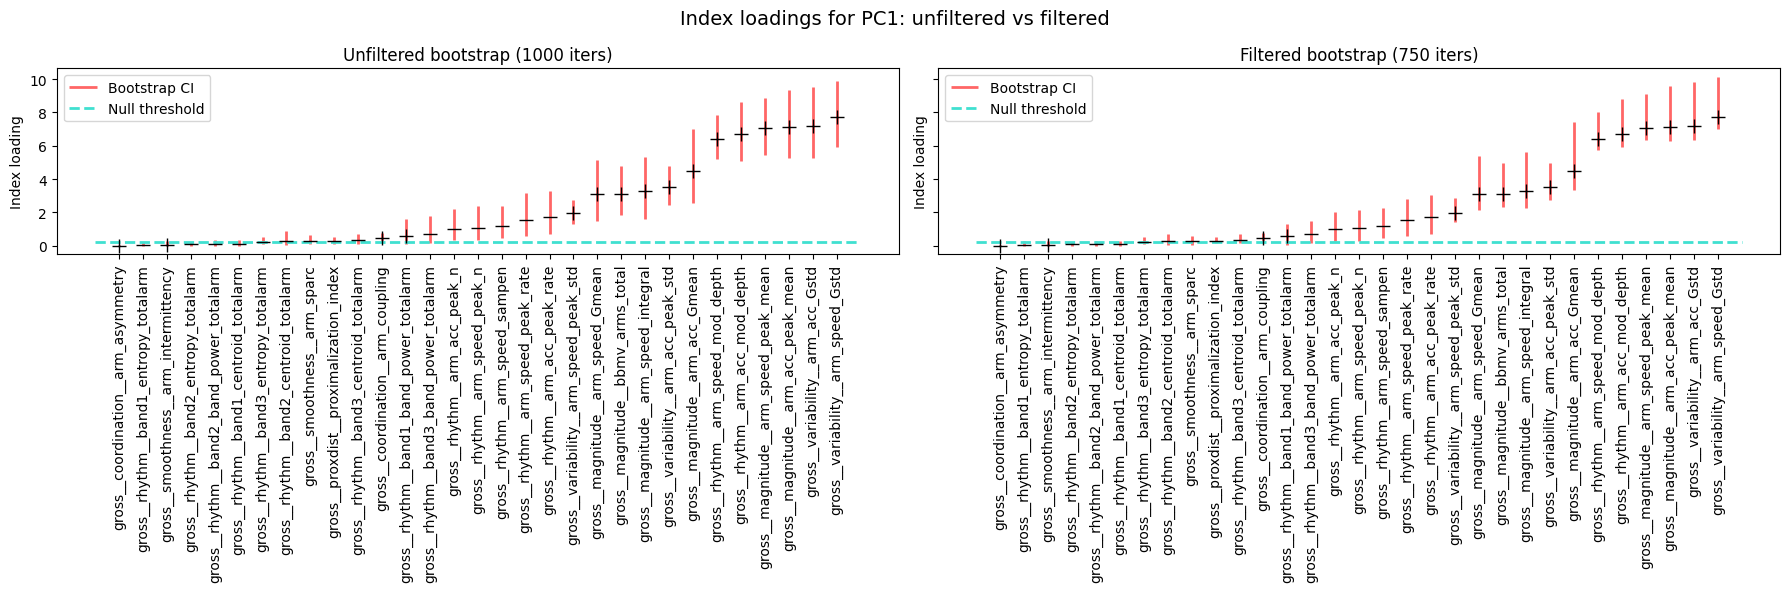

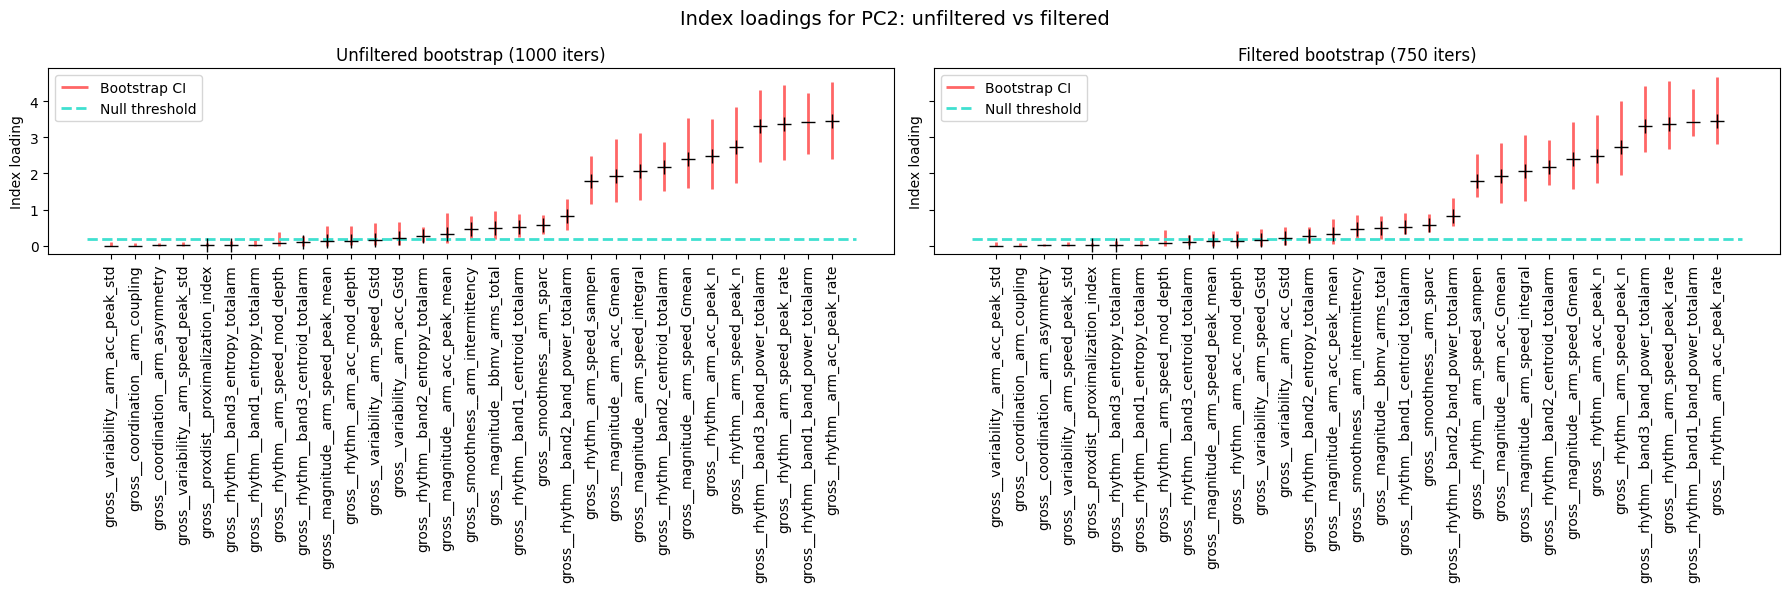

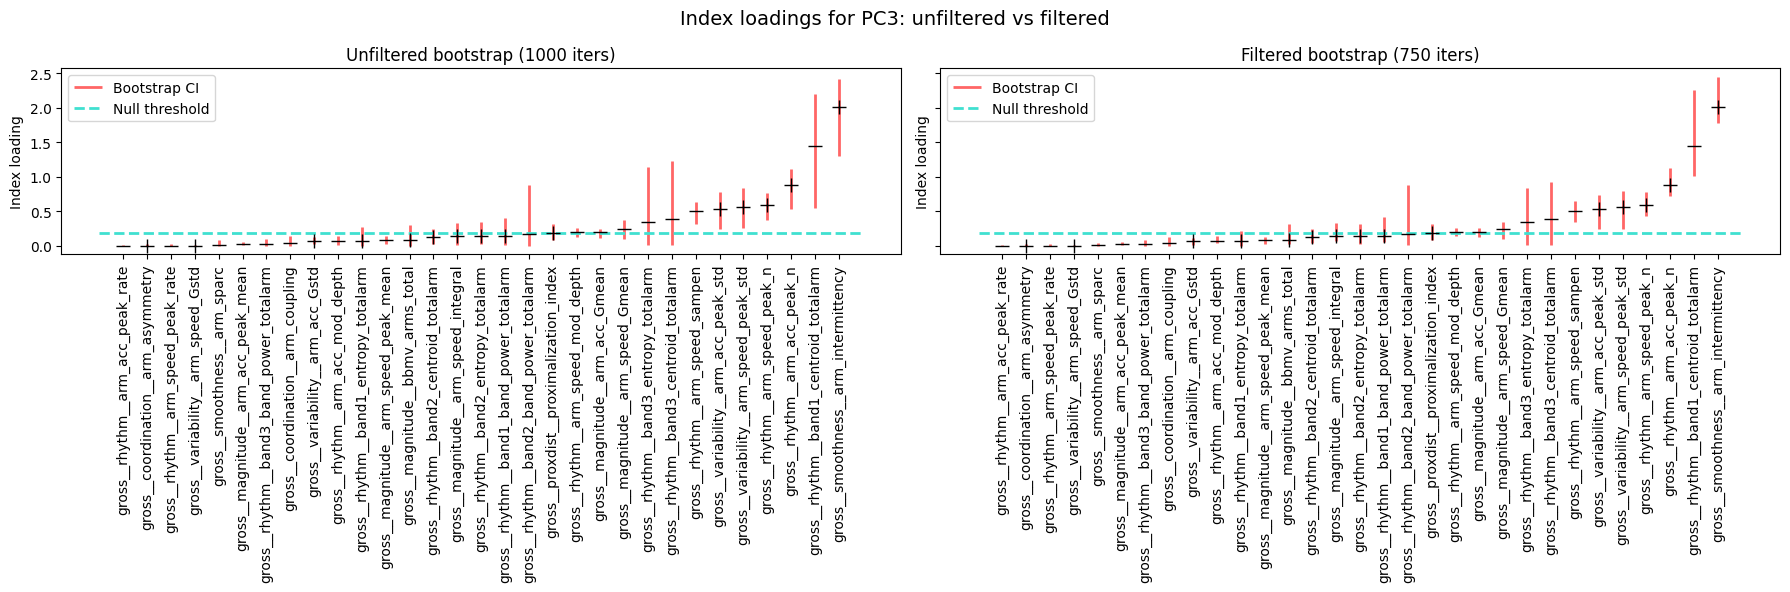

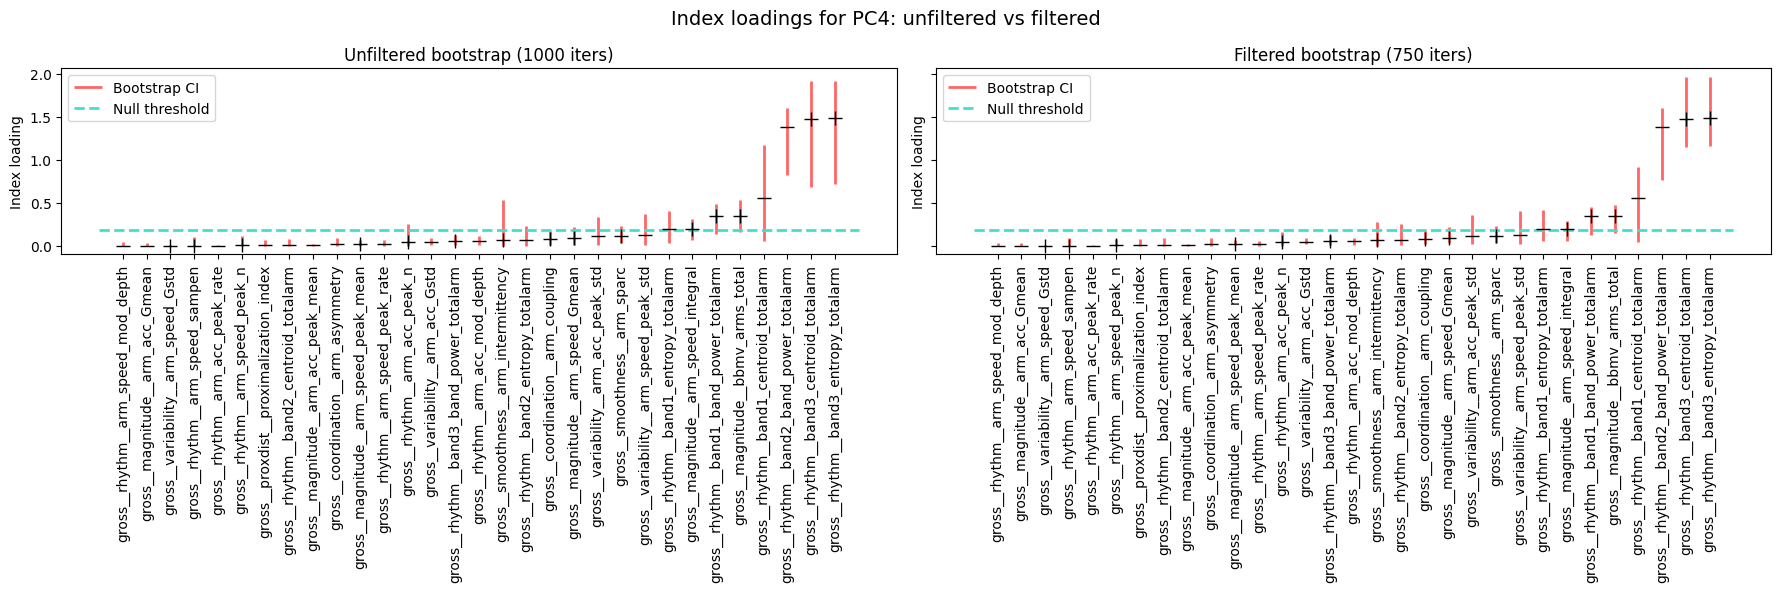

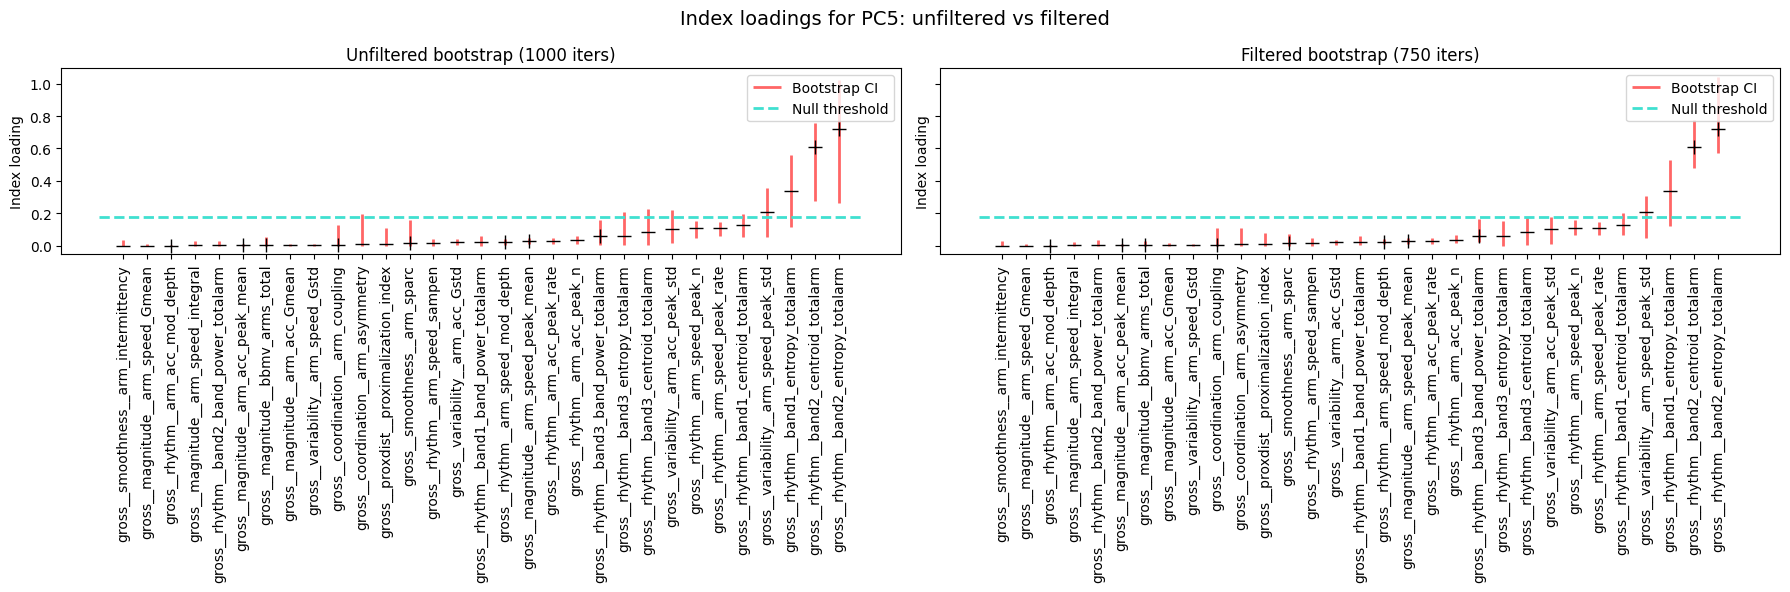

In [62]:
# Before vs after filtering, for EVERY significant PC (GSG / gross only)
for pc in np.where(sig_pc_GSG)[0]:
    plot_loadings_compare(pca_GSG, bootstrap_results_GSG, permutation_results_GSG,
                          pc_idx=int(pc), feature_names=df_clean.columns[:-1],
                          pc_name=f"PC{pc+1}")


## Features to keep (stability-aware: significant + CI vs null before/after)

In [63]:
# Stability-aware table for every significant PC (GSG / gross only).
# Same shape as GS (loadings_all.csv); becomes the authoritative loadings file for this group,
# superseding the simple export_sigvars written above.
sig_pcs = np.where(sig_pc_GSG)[0]                      # 0-based significant PC indices
tables = []
for pc in sig_pcs:
    tbl, _ = select_features_for_pc(pca_GSG, bootstrap_results_GSG, permutation_results_GSG,
                                    df_clean.columns[:-1], pc_idx=pc, verbose=False)
    tables.append(tbl.assign(PC=pc + 1))

sig_features_GSG = pd.concat(tables, ignore_index=True)

# keep ALL significant features; flag CI-vs-null status before and after stabilization
sig_features_GSG = (sig_features_GSG[sig_features_GSG["sig_obs"]]
                   .rename(columns={"stable_unfilt": "CI_above_null_before",
                                    "stable_filt":   "CI_above_null_after"})
                   [["PC", "variable", "loading_sign", "obs_index",
                     "null_thresh",
                     "boot_low_unfilt", "boot_high_unfilt",
                     "boot_low_filt",  "boot_high_filt",
                     "CI_above_null_before", "CI_above_null_after",
                     "is_anchor", "share",
                      "cum_frac", "within_50pct"]]
                   .sort_values(["PC", "obs_index"], ascending=[True, False])
                   .reset_index(drop=True))

sig_features_GSG.to_csv(os.path.join("Datasets", "loadings_gross.csv"), index=False)
sig_features_GSG


,PC,variable,loading_sign,obs_index,null_thresh,boot_low_unfilt,boot_high_unfilt,boot_low_filt,boot_high_filt,CI_above_null_before,CI_above_null_after,is_anchor,share,cum_frac,within_50pct
0,1,gross__variability__arm_speed_Gstd,1.0,7.740969,0.198627,5.918510,9.886870,7.019450,10.144692,True,True,True,0.107730,0.107730,True
1,1,gross__variability__arm_acc_Gstd,1.0,7.177856,0.197866,5.263178,9.542000,6.318690,9.827019,True,True,False,0.099894,0.207624,True
2,1,gross__magnitude__arm_acc_peak_mean,1.0,7.141022,0.231052,5.268991,9.367694,6.272663,9.606377,True,True,False,0.099381,0.307005,True
3,1,gross__magnitude__arm_speed_peak_mean,1.0,7.081914,0.206784,5.430927,8.898426,6.376747,9.107040,True,True,False,0.098558,0.405564,True
4,1,gross__rhythm__arm_acc_mod_depth,1.0,6.697538,0.206390,5.115737,8.619092,5.911674,8.826235,True,True,False,0.093209,0.498773,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,4,gross__rhythm__band1_entropy_totalarm,-1.0,0.190408,0.186115,0.035400,0.403635,0.052259,0.412219,False,False,False,0.027636,0.865921,False
64,5,gross__rhythm__band2_entropy_totalarm,1.0,0.721608,0.181732,0.260903,1.021936,0.571104,1.041930,True,True,True,0.261879,0.261879,True
65,5,gross__rhythm__band2_centroid_totalarm,1.0,0.609777,0.169062,0.275505,0.759000,0.480693,0.777514,True,True,False,0.221295,0.483174,True
66,5,gross__rhythm__band1_entropy_totalarm,-1.0,0.335996,0.176531,0.116880,0.558902,0.123454,0.529493,False,False,False,0.121936,0.605110,False


# PCA: All groups (fine only)

In [64]:
# read it
df_clean = pd.read_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'))

In [65]:
# get rid of all columns with fine_ in the name
cols_to_drop = [col for col in df_clean.columns if col.startswith('gross_')]

df_clean = df_clean.drop(columns=cols_to_drop)

In [66]:
feature_names = df_clean.columns[:-1].to_list()

# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features

df_clean['groupID'] = df_clean['groupID'].astype('category')
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler_GSF = StandardScaler()
Xz_GSF = scaler_GSF.fit_transform(X)    

# PCA transformation
pca_GSF = PCA()
x_new_GSF = pca_GSF.fit_transform(Xz_GSF)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings_GSF = pca_GSF.components_.T

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # PC1 and PC2 (the PCs you plot below)
    component = loadings_GSF[:, i]      # column i = all variables' loadings ON PC i
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(score=x_new_GSF, 
                       coeff=loadings_GSF, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                       le=le,
                        arrow_strength=arrow_strength                    )

In [67]:
# Plot
interactive_PCA_biplot(score=x_new_GSF, 
                       coeff=loadings_GSF, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=2, pc_y=3,
                       show_labels=False,
                       le=le,
                        arrow_strength=arrow_strength 
                       )

In [68]:
# Plot
interactive_PCA_biplot(score=x_new_GSF, 
                       coeff=loadings_GSF, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=3, pc_y=4,
                       show_labels=False,
                       le=le,
                        arrow_strength=arrow_strength 
                       )

## Bootstraping and significance

In [69]:
bootstrap_results_GSF = bootstrap_pca(Xz_GSF)
permutation_results_GSF = permutation_pca(Xz_GSF)

# determine significant PCs
var_explained_GSF = pca_GSF.explained_variance_ratio_
null_var_thresh_GSF = permutation_results_GSF["null_eig_thresh"] / np.sum(pca_GSF.explained_variance_)  # convert eig to variance ratio
sig_pc_null_GSF = var_explained_GSF > null_var_thresh_GSF

sig_pc_effect_GSF = var_explained_GSF > 0.05  # 5% cut-off
sig_pc_GSF = sig_pc_null_GSF & sig_pc_effect_GSF

print("Significant PCs:")
for i, sig in enumerate(sig_pc_GSF, start=1):
    print(f"PC{i}: significant = {sig}, var explained = {var_explained_GSF[i-1]:.3f}")



Significant PCs:
PC1: significant = True, var explained = 0.441
PC2: significant = True, var explained = 0.135
PC3: significant = True, var explained = 0.087
PC4: significant = True, var explained = 0.080
PC5: significant = False, var explained = 0.057
PC6: significant = False, var explained = 0.054
PC7: significant = False, var explained = 0.041
PC8: significant = False, var explained = 0.032
PC9: significant = False, var explained = 0.021
PC10: significant = False, var explained = 0.015
PC11: significant = False, var explained = 0.013
PC12: significant = False, var explained = 0.011
PC13: significant = False, var explained = 0.010
PC14: significant = False, var explained = 0.002
PC15: significant = False, var explained = 0.001
PC16: significant = False, var explained = 0.000


## Identify sig variables

In [70]:
df_sig_vars_GSF = identify_sigvar(pca_GSF, bootstrap_results_GSF, permutation_results_GSF, df_clean)
df_sig_vars_GSF[df_sig_vars_GSF["sig_loading"]].sort_values(["PC", "index_loading"], ascending=[True, False])

,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
8,1,fine__handshape__handshape_size_mean,0.318178,5.041760,3.210974,7.954237,0.000326,0.317668,True
2,1,fine__handshape__thumb_index_mean,0.312597,4.866444,2.747018,8.871251,0.000968,0.317521,True
9,1,fine__variability__handshape_size_std,0.311952,4.846379,2.656811,8.588309,0.000540,0.311352,True
0,1,fine__handshape__fingertip_spread_mean,0.309045,4.756471,3.119746,7.314711,0.000601,0.291771,True
4,1,fine__handshape__mcp_tip_mean,0.303984,4.601986,2.422739,8.697689,0.000725,0.326462,True
1,1,fine__variability__fingertip_spread_std,0.301335,4.522116,2.321795,8.840112,0.000427,0.300936,True
3,1,fine__variability__thumb_index_std,0.282127,3.963970,2.232207,6.399670,0.000623,0.321487,True
10,1,fine__variability__handshape_variability,0.280516,3.918838,2.326456,6.029909,0.000774,0.306675,True
5,1,fine__variability__mcp_tip_std,0.267686,3.568567,1.238306,8.253148,0.000519,0.321697,True
11,1,fine__magnitude__flexion_speed_mean,0.236613,2.788180,1.211003,5.290958,0.000355,0.292070,True


In [71]:
sig_idx = np.where(sig_pc_GSF)[0]                       # significant PCs (null AND >=5%)
pc_cols = [f"PC{i+1}" for i in sig_idx]
scores  = pd.DataFrame(x_new_GSF[:, sig_idx], columns=pc_cols)

meta = (sampled_df[['group', 'groupID', 'concept']]
        .reset_index(drop=True)
        .rename(columns={'group': 'participant'}))
assert len(meta) == len(scores), "row mismatch — metadata not aligned with PCA scores!"

out = pd.concat([scores, meta], axis=1)
for row in out.itertuples():
    if row.participant.startswith('IP'):
        out.loc[row.Index, 'participant'] = row.participant.split('_')[0]

out.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_fine.csv'), index=False)

## Filtered vs unfiltered loadings (per significant PC)

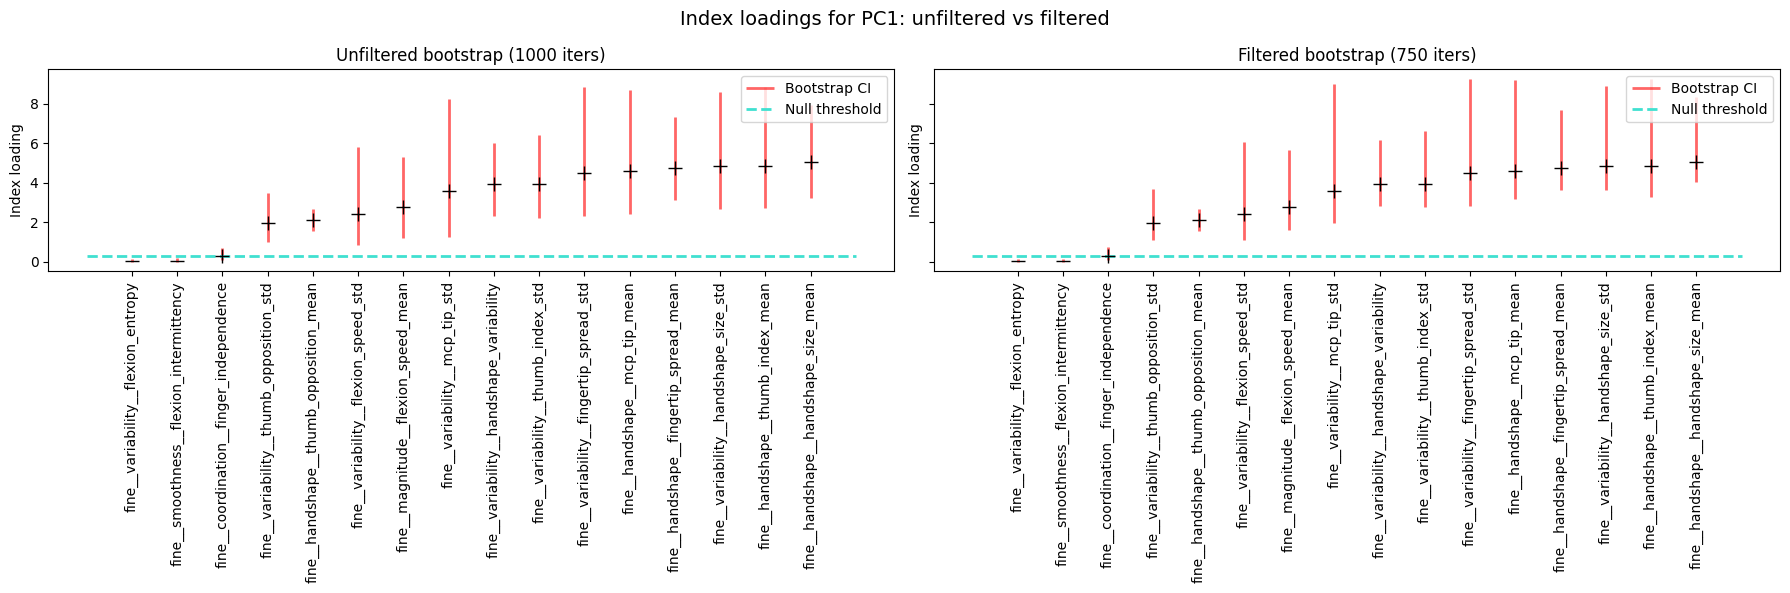

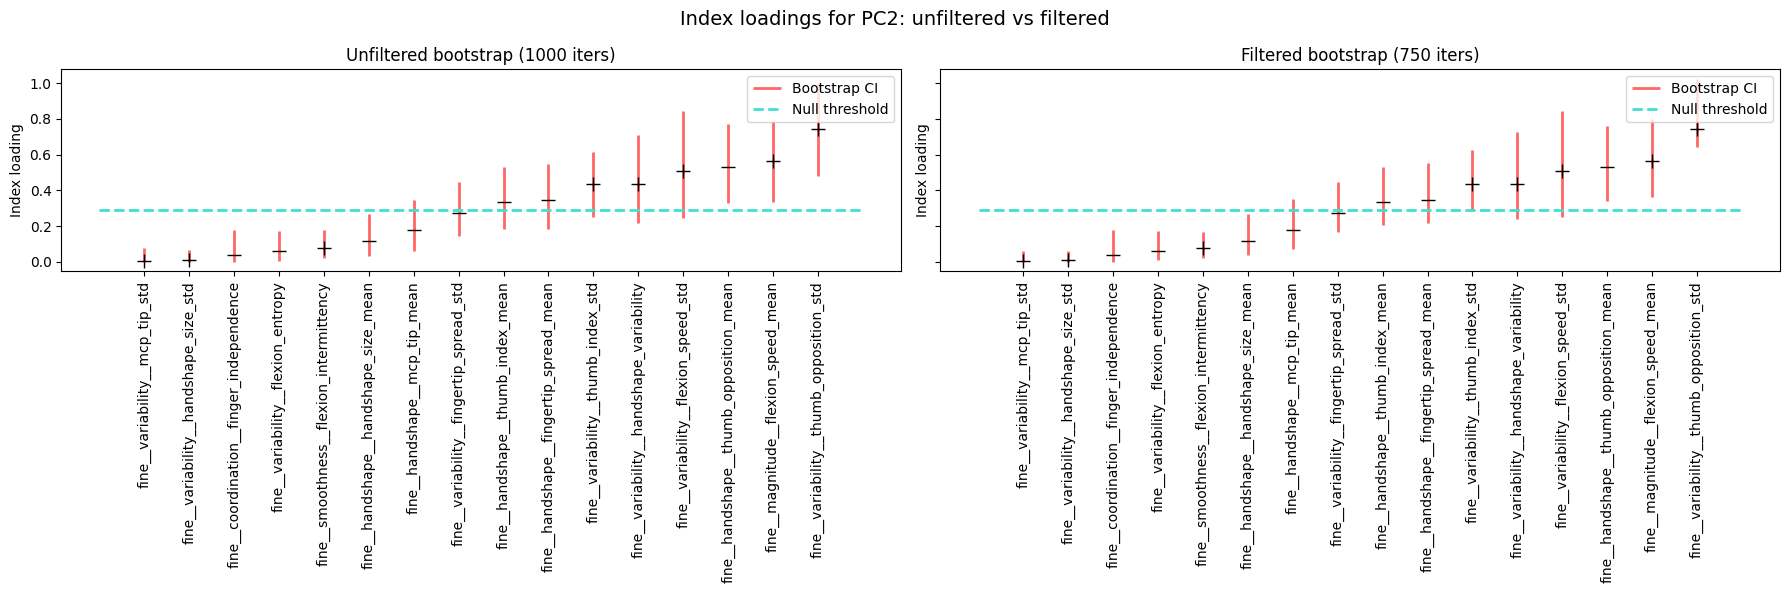

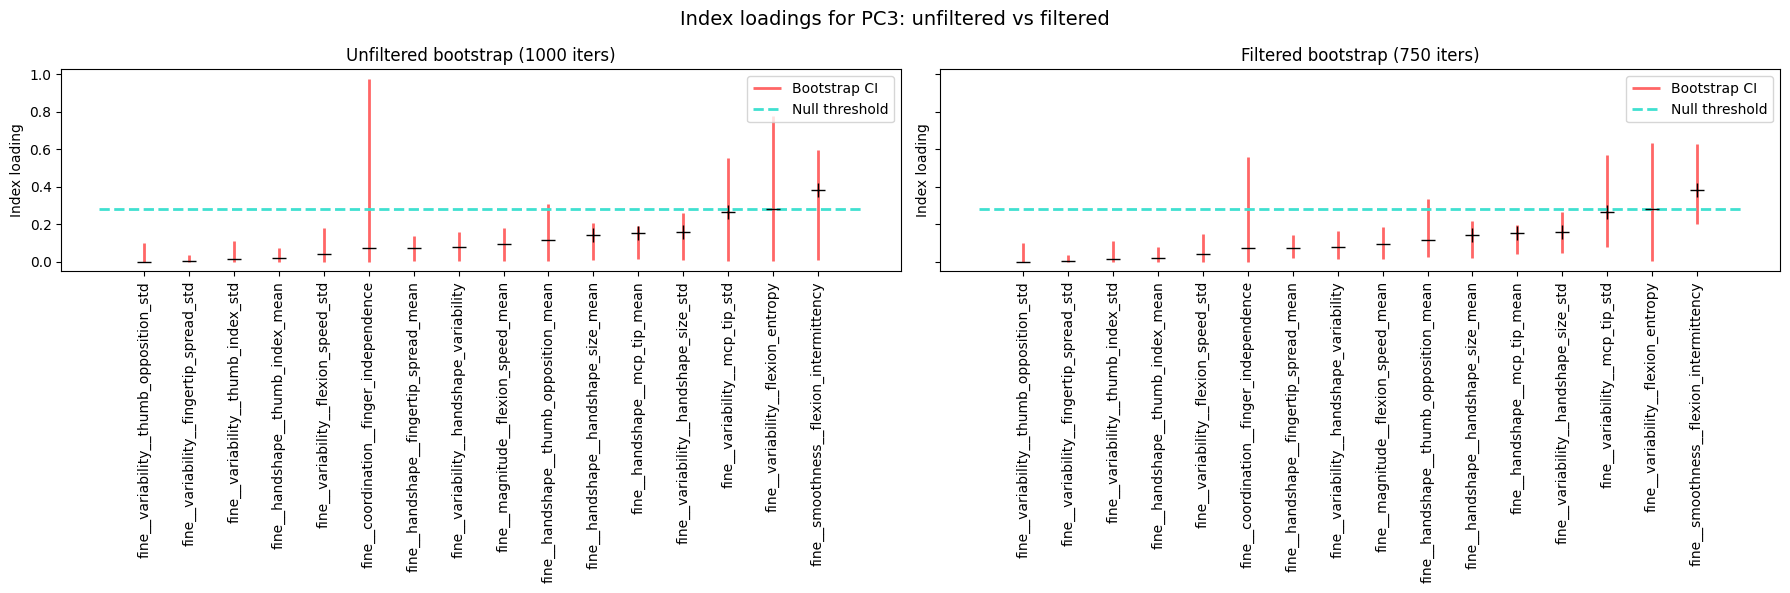

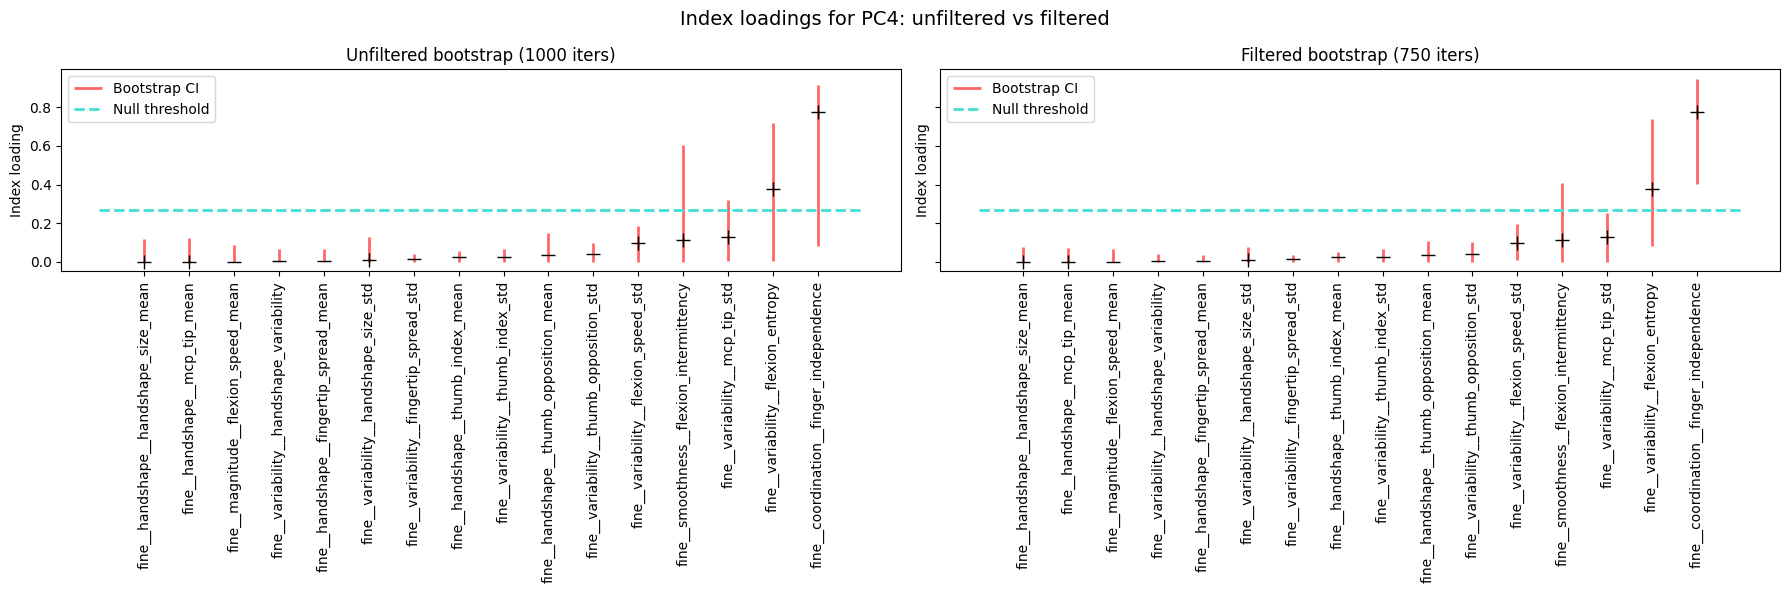

In [72]:
# Before vs after filtering, for EVERY significant PC (GSF / fine only)
for pc in np.where(sig_pc_GSF)[0]:
    plot_loadings_compare(pca_GSF, bootstrap_results_GSF, permutation_results_GSF,
                          pc_idx=int(pc), feature_names=df_clean.columns[:-1],
                          pc_name=f"PC{pc+1}")


## Features to keep (stability-aware: significant + CI vs null before/after)

In [73]:
# Stability-aware table for every significant PC (GSF / fine only).
# Same shape as GS (loadings_all.csv); becomes the authoritative loadings file for this group,
# superseding the simple export_sigvars written above.
sig_pcs = np.where(sig_pc_GSF)[0]                      # 0-based significant PC indices
tables = []
for pc in sig_pcs:
    tbl, _ = select_features_for_pc(pca_GSF, bootstrap_results_GSF, permutation_results_GSF,
                                    df_clean.columns[:-1], pc_idx=pc, verbose=False)
    tables.append(tbl.assign(PC=pc + 1))

sig_features_GSF = pd.concat(tables, ignore_index=True)

# keep ALL significant features; flag CI-vs-null status before and after stabilization
sig_features_GSF = (sig_features_GSF[sig_features_GSF["sig_obs"]]
                   .rename(columns={"stable_unfilt": "CI_above_null_before",
                                    "stable_filt":   "CI_above_null_after"})
                   [["PC", "variable", "loading_sign", "obs_index",
                     "null_thresh",
                     "boot_low_unfilt", "boot_high_unfilt",
                     "boot_low_filt",  "boot_high_filt",
                     "CI_above_null_before", "CI_above_null_after",
                     "is_anchor", "share",
                      "cum_frac", "within_50pct"]]
                   .sort_values(["PC", "obs_index"], ascending=[True, False])
                   .reset_index(drop=True))

sig_features_GSF.to_csv(os.path.join("Datasets", "loadings_fine.csv"), index=False)
sig_features_GSF


,PC,variable,loading_sign,obs_index,null_thresh,boot_low_unfilt,boot_high_unfilt,boot_low_filt,boot_high_filt,CI_above_null_before,CI_above_null_after,is_anchor,share,cum_frac,within_50pct
0,1,fine__handshape__handshape_size_mean,1.0,5.041760,0.317668,3.210974,7.954237,4.038395,8.321712,True,True,True,0.101237,0.101237,True
1,1,fine__handshape__thumb_index_mean,1.0,4.866444,0.317521,2.747018,8.871251,3.303582,9.276078,True,True,False,0.097717,0.198954,True
2,1,fine__variability__handshape_size_std,1.0,4.846379,0.311352,2.656811,8.588309,3.643493,8.874108,True,True,False,0.097314,0.296268,True
3,1,fine__handshape__fingertip_spread_mean,1.0,4.756471,0.291771,3.119746,7.314711,3.614026,7.693411,True,True,False,0.095509,0.391776,True
4,1,fine__handshape__mcp_tip_mean,1.0,4.601986,0.326462,2.422739,8.697689,3.184537,9.216591,True,True,False,0.092407,0.484183,True
5,1,fine__variability__fingertip_spread_std,1.0,4.522116,0.300936,2.321795,8.840112,2.835419,9.261871,True,True,False,0.090803,0.574986,False
6,1,fine__variability__thumb_index_std,1.0,3.963970,0.321487,2.232207,6.399670,2.773225,6.632187,True,True,False,0.079595,0.654581,False
7,1,fine__variability__handshape_variability,1.0,3.918838,0.306675,2.326456,6.029909,2.807503,6.191162,True,True,False,0.078689,0.733270,False
8,1,fine__variability__mcp_tip_std,1.0,3.568567,0.321697,1.238306,8.253148,1.994535,9.013399,True,True,False,0.071656,0.804926,False
9,1,fine__magnitude__flexion_speed_mean,1.0,2.788180,0.292070,1.211003,5.290958,1.612562,5.681515,True,True,False,0.055986,0.860912,False


# Summary across all three groups

In [74]:
# Combined stability summary across all three groups (uses the three sig_features_* tables)
summary_all = pd.concat([
    sig_features_GS.assign(group="all"),
    sig_features_GSG.assign(group="gross"),
    sig_features_GSF.assign(group="fine"),
], ignore_index=True)

# per group x PC: how many features are significant, and how many keep their CI above null
overview = (summary_all
            .groupby(["group", "PC"])
            .agg(n_significant=("variable", "size"),
                 CI_above_null_before=("CI_above_null_before", "sum"),
                 CI_above_null_after=("CI_above_null_after", "sum"))
            .reset_index())

summary_all.to_csv(os.path.join("Datasets", "loadings_all_groups.csv"), index=False)
overview


,group,PC,n_significant,CI_above_null_before,CI_above_null_after
0,all,1,37,15,23
1,all,2,33,1,14
2,all,3,29,8,16
3,all,4,18,11,11
4,all,5,13,5,6
5,fine,1,14,13,13
6,fine,2,8,3,3
7,fine,3,2,0,0
8,fine,4,2,0,1
9,gross,1,25,18,18


# PCA: Sign-only (drop gesturers) — complementary within-sign analysis

The pooled PCA is dominated by the gesture–sign contrast (gesturers are the most extreme
group), which makes it the right basis for **conventionalization** but leaves the
**within-sign / acquisition** structure under-resolved — learner→native variation is pushed
onto minor components. This section refits the PCA on **signers only** (drop `Gesture`; keep
`Learner_1`, `Learner_2`, `Sign`), **re-standardizing features within the sign-only subset**,
so the leading components describe variation *among signers*.

Complementary, not a replacement: these scores live on a *different basis* than the pooled
PCA, so they cannot carry the gesture-vs-sign cross-trajectory (nesting) claim — they answer
"what structures within-sign variation, and where does acquisition sit inside it." It stays
unsupervised (never sees the L1/L2/native labels), so modelling these scores by group is not
circular. Exports mirror the pooled pipeline with a `_signonly` suffix
(`pca_scores_{all,gross,fine}_signonly.csv`, `loadings_{...}_signonly.csv`, plus `_varimax`),
so they feed the brms Rmd unchanged.

**Keep-or-drop criterion:** report this only if it surfaces *significant* within-sign
components with no counterpart in the pooled solution (real structure the gesture axis was
masking). Power caveat baked in: dropping gesturers leaves ~16 participants and only 2
natives, so eigenvalue/loading significance is shakier and the native endpoint stays
underpowered regardless of basis.

## Prep: signers-only subset, aligned with metadata

In [75]:
# fresh full feature frame (all features, LP already excluded); drop gesturers, keep row alignment
df_full = pd.read_csv(os.path.join(features, 'sampled_merged_sapiens.csv'))

# drop last column (concept)
df_full = df_full.iloc[:, :-1]

# sampled_df (metadata source) and df_full are assumed row-aligned by the pooled exports;
# verify before masking so we never misalign scores and metadata
_sd = sampled_df.reset_index(drop=True)
assert len(_sd) == len(df_full), "sampled_df and feature frame differ in length — alignment broken"
assert np.array_equal(_sd['groupID'].to_numpy(), df_full['groupID'].to_numpy()), \
    "row order of sampled_df and feature frame disagree — do not mask"

keep = (df_full['groupID'] != 'Gesture').to_numpy()          # signers = everything but Gesture
print("sign-only rows:", int(keep.sum()), "of", len(keep))
print(df_full.loc[keep, 'groupID'].value_counts())

df_so      = df_full.loc[keep].reset_index(drop=True)        # features (+ groupID as last column)
sampled_so = _sd.loc[keep].reset_index(drop=True)            # aligned metadata

# domain-separated feature frames (groupID stays the last column in each)
blocks_so = {
    "all":   df_so.copy(),
    "gross": df_so.drop(columns=[c for c in df_so.columns if c.startswith('fine_')]),
    "fine":  df_so.drop(columns=[c for c in df_so.columns if c.startswith('gross_')]),
}
for tag, b in blocks_so.items():
    print(f"{tag:5s}: {b.shape[1]-1} features")

sign-only rows: 739 of 989
groupID
Learner_1    249
Learner_2    247
Sign         243
Name: count, dtype: int64
all  : 47 features
gross: 31 features
fine : 16 features


## Unrotated: fit + significance + export (all / gross / fine)

In [76]:
# one function reproducing the pooled per-block pipeline, on the sign-only subset
def run_signonly_block(df_block, sampled_block, tag, n_boot=1000):
    feature_names = df_block.columns[:-1].to_list()
    X  = df_block.iloc[:, :-1].values

    scaler = StandardScaler()                    # RE-STANDARDIZE within the sign-only subset
    Xz     = scaler.fit_transform(X)
    pca    = PCA()
    x_new  = pca.fit_transform(Xz)

    boot = bootstrap_pca(Xz, n_boot=n_boot)
    perm = permutation_pca(Xz, n_boot=n_boot)

    var_exp  = pca.explained_variance_ratio_
    null_thr = perm["null_eig_thresh"] / np.sum(pca.explained_variance_)   # eig -> variance ratio
    sig_pc   = (var_exp > null_thr) & (var_exp > 0.05)                     # null AND >=5%, pooled rule
    print(f"[{tag}] significant PCs: {list(np.where(sig_pc)[0] + 1)}  "
          f"var={np.round(var_exp[sig_pc], 3)}")

    df_sig_vars = identify_sigvar(pca, boot, perm, df_block)   # feature order for varimax step

    sig_idx = np.where(sig_pc)[0]
    if len(sig_idx):
        # ---- scores (mirror of pca_scores_*.csv) ----
        pc_cols = [f"PC{i+1}" for i in sig_idx]
        scores  = pd.DataFrame(x_new[:, sig_idx], columns=pc_cols)
        meta = (sampled_block[['group', 'groupID', 'concept']]
                .reset_index(drop=True).rename(columns={'group': 'participant'}))
        assert len(meta) == len(scores), "row mismatch — metadata not aligned with scores!"
        out = pd.concat([scores, meta], axis=1)
        for row in out.itertuples():
            if isinstance(row.participant, str) and row.participant.startswith('IP'):
                out.loc[row.Index, 'participant'] = row.participant.split('_')[0]
        out.to_csv(os.path.join(curfolder, 'Datasets', f'pca_scores_{tag}_signonly.csv'), index=False)

        # ---- loadings (mirror of loadings_*.csv) ----
        tables = []
        for pc in sig_idx:
            tbl, _ = select_features_for_pc(pca, boot, perm, feature_names, pc_idx=pc, verbose=False)
            tables.append(tbl.assign(PC=pc + 1))
        sig_features = (pd.concat(tables, ignore_index=True)
                        .query("sig_obs")
                        .rename(columns={"stable_unfilt": "CI_above_null_before",
                                         "stable_filt":   "CI_above_null_after"})
                        [["PC", "variable", "loading_sign", "obs_index", "null_thresh",
                          "boot_low_unfilt", "boot_high_unfilt", "boot_low_filt", "boot_high_filt",
                          "CI_above_null_before", "CI_above_null_after", "is_anchor", "share", "cum_frac", "within_50pct"]]
                        .sort_values(["PC", "obs_index"], ascending=[True, False])
                        .reset_index(drop=True))
        sig_features.to_csv(os.path.join("Datasets", f"loadings_{tag}_signonly.csv"), index=False)
    else:
        print(f"[{tag}] no significant PCs — nothing exported.")

    return dict(tag=tag, scaler=scaler, pca=pca, x_new=x_new, Xz=Xz,
                boot=boot, perm=perm, sig_pc=sig_pc, df_sig_vars=df_sig_vars,
                feature_names=feature_names)

signonly = {tag: run_signonly_block(b, sampled_so, tag) for tag, b in blocks_so.items()}

[all] significant PCs: [1, 2, 3, 4, 5]  var=[0.167 0.154 0.134 0.093 0.061]
[gross] significant PCs: [1, 2, 3, 4, 5]  var=[0.249 0.196 0.111 0.09  0.054]
[fine] significant PCs: [1, 2, 3, 4]  var=[0.445 0.148 0.082 0.075]


## Create final table

In [77]:
def variance_table(pca, boot, sig_pc, domain, basis):
    ve  = pca.explained_variance_ratio_
    bve = boot["boot_eigs"] / boot["boot_eigs"].sum(axis=1, keepdims=True)   # per-draw ratios
    idx = np.where(sig_pc)[0]
    return pd.DataFrame({
        "basis": basis, "domain": domain, "PC": idx + 1,
        "var_exp":  ve[idx],
        "var_low":  np.percentile(bve[:, idx], 2.5,  axis=0),
        "var_high": np.percentile(bve[:, idx], 97.5, axis=0),
        "cum_var":  np.cumsum(ve)[idx],
    })

# pooled PCA (all signers + gesturers)
pooled = {
    "all":   (pca_GS,  bootstrap_results_GS,  sig_pc_GS),
    "gross": (pca_GSG, bootstrap_results_GSG, sig_pc_GSG),
    "fine":  (pca_GSF, bootstrap_results_GSF, sig_pc_GSF),
}

var_tab = pd.concat(
    # pooled: all / gross / fine
    [variance_table(p, b, s, dom, "pca") for dom, (p, b, s) in pooled.items()] +
    # sign-only: all / gross / fine
    [variance_table(signonly[dom]["pca"], signonly[dom]["boot"], signonly[dom]["sig_pc"], dom, "signonly")
     for dom in ["all", "gross", "fine"]],
    ignore_index=True,
)

var_tab.to_csv(os.path.join("Datasets", "pca_variance_explained.csv"), index=False)
var_tab

,basis,domain,PC,var_exp,var_low,var_high,cum_var
0,pca,all,1,0.186914,0.175014,0.214880,0.186914
1,pca,all,2,0.152299,0.130725,0.178136,0.339212
2,pca,all,3,0.124549,0.108982,0.134543,0.463762
3,pca,all,4,0.083888,0.075691,0.091874,0.547649
4,pca,all,5,0.059167,0.053970,0.065216,0.606817
5,pca,gross,1,0.273166,0.249589,0.302314,0.273166
6,pca,gross,2,0.186711,0.166953,0.206622,0.459878
7,pca,gross,3,0.098146,0.089241,0.109106,0.558024
8,pca,gross,4,0.084586,0.076651,0.091654,0.642610
9,pca,gross,5,0.053493,0.048895,0.059643,0.696103
